# 02 · Focal-plane polarization atlas

**Vectorial diffraction of structured light with an ideal high-NA objective**

This tutorial calculates and visualizes the three complex electric-field components of Gaussian, Laguerre–Gaussian (LG), cylindrical-vector and full-Poincaré beams at the focal plane. Its purpose is to connect the incident pupil polarization, vectorial diffraction and the resulting three-dimensional polarization structure.

### Learning objectives

- Understand why tightly focused light requires a vectorial diffraction model.
- Derive the five radial Bessel integrals from the Richards–Wolf expression.
- Construct structured incident fields through coherent mode superpositions.
- Interpret Cartesian intensity and phase maps, polarization ellipses and their principal axes.
- Explore the computed fields with an interactive, offline HTML viewer.

### Contents

| Section | Topic |
| --- | --- |
| A | Theory: vectorial diffraction and analytical reduction |
| B | Installation, optical parameters and numerical implementation |
| C | Observables and visualization |
| 1 | Gaussian beams (6 states) |
| 2 | Laguerre–Gaussian beams, charges +1 and −1 (12 states) |
| 3 | Cylindrical-vector beams (4 states) |
| 4 | Full-Poincaré beams (3 states) |
| 5 | Interpretation, limitations and numerical checks |
| 6 | Reference-data generation and ZIP download |

### Getting started

A standard CPU runtime in Google Colab is sufficient. Read Sections A–C, execute the setup and function-definition cells once, then run the calculation and visualization cells for the desired beam. Each example can be evaluated independently after initialization. The HTML button below a static plot opens an interactive explorer **only on request**; a running Python kernel is not required after the HTML has been generated.

**Scope.** Monochromatic light, homogeneous focal medium, ideal aplanatic objective, transverse incident Jones field, and focal plane $z=0$. The numerical model uses $p=0$ LG-like pupil modes and double-precision complex fields.

**Background.** This notebook adapts Chapter 2 and Appendix A of M. F. Ferrer-García's PhD thesis and the repository's [Tutorial 01](https://github.com/mffg1993/TightFocusingSolutions/blob/main/tutorials/01_Thesis_Bessel_Integral_Decomposition.ipynb). All equations and numerical definitions needed for the examples are provided below.

## **A. Theory of vectorial focusing**

### **A.1. Physical model and conventions**

Consider a monochromatic incident beam entering an ideal objective with focal length $f$, numerical aperture $\mathrm{NA}$ and homogeneous focal-medium index $n$. The objective redirects the incident transverse field toward the geometrical focus. The resulting field is the coherent superposition of these rotated plane waves.

We use the time convention $\mathrm{Re}[\mathbf E e^{-i\omega t}]$ and forward propagation $e^{+ikz}$. The origin is the geometrical focus, and the optical axis is $z$. In the general derivation we retain $z$; the atlas evaluates only $z=0$.



#### **From transverse pupil to three-dimensional field**

In the paraxial approximation, the electric field is commonly described by a scalar envelope multiplying a fixed transverse polarization vector. For high numerical apertures this approximation fails: the objective redirects the constituent wavevectors, and the local electric-field polarization must rotate to remain orthogonal to each propagation direction. A significant longitudinal component can arise even when the incident beam has **zero longitudinal field**.

The thesis introduces a reference sphere of radius $f$ about the focal point. An incident transverse Jones field is transformed on this sphere before the outgoing rays interfere in the focal region. We distinguish three coordinate descriptions:

- Entrance pupil: $(x_p,y_p)$, with radial coordinate $r_p=f\sin\theta$ for an ideal lens obeying the Abbe sine condition.
- Focal region: $(\rho,\varphi,z)$, with $x=\rho\cos\varphi$ and $y=\rho\sin\varphi$.
- Rays: polar/azimuthal angles $(\theta,\phi)$, with $\theta\leq\alpha$, $\alpha=\arcsin(\mathrm{NA}/n)$.

The optical wavenumber is $k=2\pi n/\lambda_0$, where $\lambda_0$ is the **vacuum** wavelength. Equivalently, $k=2\pi/\lambda$ for the **medium** wavelength $\lambda=\lambda_0/n$. The wavelength convention determines both the propagation phase and dimensional prefactors.

### **A.2. Aplanatic polarization transformation **

The thesis writes $\mathbf T=\sqrt{\cos\theta}\,\mathbf R$ with

$$
\mathbf R(\theta,\phi)=
\begin{pmatrix}
\cos\theta\cos^2\phi+\sin^2\phi &
(\cos\theta-1)\sin\phi\cos\phi & \sin\theta\cos\phi\\
(\cos\theta-1)\sin\phi\cos\phi &
\cos\theta\sin^2\phi+\cos^2\phi & \sin\theta\sin\phi\\
-\sin\theta\cos\phi & -\sin\theta\sin\phi & \cos\theta
\end{pmatrix}.
$$

The **first two columns** act on the incident transverse field, $\mathbf E_\mathrm{in}=(E_x^\mathrm{in},E_y^\mathrm{in},0)^\mathsf{T}$. The third column is irrelevant for this specific incident-field assumption. The factor $\sqrt{\cos\theta}$ is the aplanatic apodization arising from energy-flow conservation. Geometrically, radial pupil polarization is rotated into the ray's polar direction, while azimuthal polarization is left unchanged.

Check: $\mathbf R^\mathsf T\mathbf R=\mathbb I$ and, for its first two columns, $\mathbf s\cdot\mathbf R_{:,j}=0$, with $\mathbf s=(\sin\theta\cos\phi,\sin\theta\sin\phi,\cos\theta)$.

### A.3. Richards–Wolf diffraction integral — thesis Eqs. (2.1) and (2.3)

Under the harmonic convention $\mathbf E(t)=\mathrm{Re}[\mathbf E e^{-i\omega t}]$, the complex field in the focal volume is

$$
\boxed{
\mathbf E(\rho,\varphi,z)=
-\frac{ikf}{2\pi}e^{-ikf}
\int_{0}^{\alpha}\!\int_0^{2\pi}
\sqrt{\cos\theta}\,
\mathbf R(\theta,\phi)\mathbf E_{\rm in}(\theta,\phi)\,
e^{ik[z\cos\theta+\rho\sin\theta\cos(\phi-\varphi)]}
\sin\theta\,d\phi\,d\theta .
}
$$

This makes explicit the complete propagation phase that is somewhat compressed in the typeset thesis Eq. (2.3). We **omit the constant factor** $e^{-ikf}$ in the numerical notebooks: it changes the global phase but not intensity or normalized phase differences. The prefactor $-ikf/(2\pi)$ is kept. If absolute phase is important, restore the factor in both the decomposition and the independent reference integral.

The 2D angular integration is valid for an ideal **aplanatic** objective in a **homogeneous** focal medium, without interfaces or aberration functions. The pupil may be described by a transverse complex Jones field, but the five-integral reduction below assumes a single azimuthal harmonic multiplied by a *spatially uniform* Jones vector.

### **A.4. Incident Laguerre–Gaussian-like pupil**

For radial index $p=0$, the thesis chooses

$$
\mathbf E_{\rm in}(\theta,\phi)=h_\ell(\theta)\,e^{i\ell\phi}
\begin{pmatrix}\cos\eta\\e^{i\chi}\sin\eta\\0\end{pmatrix},
\qquad
h_\ell(\theta)=
\left(\frac{\sin\theta}{\sin\alpha}\right)^{|\ell|}
\exp\left[-\left(\frac{\sin\theta}{\sin\alpha}\right)^2\right].
$$

The mode charge $\ell$ is an integer. $\eta$ controls the relative amplitudes of x and y polarization and $\chi$ their relative phase. The notation is proportional: a pupil-power normalization can be supplied separately. In this atlas the pupil filling parameter is fixed to one; Tutorial 01 also permits varying it.

### **A.5. Analytical azimuthal integration**

The azimuthal integral can be done analytically. The **Jacobi–Anger identity** is

$$
e^{i t\cos(\phi-\varphi)}
=\sum_{m=-\infty}^{\infty}i^mJ_m(t)e^{im(\phi-\varphi)}.
$$

Together with the Fourier orthogonality relation

$$
\int_0^{2\pi}e^{i(m-n)\phi}\,d\phi=2\pi\delta_{mn},
$$

this implies, for **any integer** $\ell+s$,

$$
\int_0^{2\pi}
e^{i(\ell+s)\phi}
e^{ik\rho\sin\theta\cos(\phi-\varphi)}\,d\phi
=2\pi\,i^{\ell+s}e^{i(\ell+s)\varphi}
J_{\ell+s}(k\rho\sin\theta).
$$

Because the transverse lens-matrix elements contain harmonics $s=0,\pm2$ and longitudinal elements contain $s=\pm1$, **only five Bessel orders are needed**:

$$
\ell,\quad\ell+2,\quad\ell-2,\quad\ell+1,\quad\ell-1.
$$

This reduction is exact for a single azimuthal harmonic, before angular quadrature. The remaining $\theta$-integrals generally require numerical evaluation. It is not a paraxial approximation.

### **A.6. Five Bessel integrals and vector field reconstruction**

Define the complex angular weight (the thesis notation)

$$
G_\ell(\theta,z)=\sqrt{\cos\theta}\,\sin\theta
\left(\frac{\sin\theta}{\sin\alpha}\right)^{|\ell|}
\exp\left[-\frac{\sin^2\theta}{\sin^2\alpha}\right]
e^{ikz\cos\theta},\qquad
u=k\rho\sin\theta.
$$

For $\lambda=\lambda_0/n$, the first three integrals agree with thesis Eqs. (2.9a)–(2.9c):

$$
\begin{aligned}
I_1&=-\frac{\pi i^{\ell+1}f}{\lambda}e^{i\ell\varphi}
\int_0^\alpha G_\ell(\theta,z)(1+\cos\theta)J_\ell(u)\,d\theta,\\[3pt]
I_2&=-\frac{\pi i^{\ell+1}f}{\lambda}e^{i(\ell+2)\varphi}
\int_0^\alpha G_\ell(\theta,z)(1-\cos\theta)J_{\ell+2}(u)\,d\theta,\\[3pt]
I_3&=-\frac{\pi i^{\ell+1}f}{\lambda}e^{i(\ell-2)\varphi}
\int_0^\alpha G_\ell(\theta,z)(1-\cos\theta)J_{\ell-2}(u)\,d\theta.
\end{aligned}
$$

**Correction to the printed thesis Eqs. (2.9d)–(2.9e):** the longitudinal angular weight requires an *additional* $\sin\theta$ relative to $G_\ell$, because the longitudinal lens-matrix elements contain $-\sin\theta\cos\phi$ and $-\sin\theta\sin\phi$. The printed Eq. (2.9d,e) omits that explicit factor; however, the thesis's **Appendix A Mathematica functions** `LGxz` and `LGyz` do contain `Sin[Theta]^2` (rather than `Sin[Theta]`). Thus the mathematically consistent forms used here are

$$
\boxed{\begin{aligned}
I_4&=+\frac{\pi i^\ell f}{\lambda}e^{i(\ell+1)\varphi}
\int_0^\alpha G_\ell(\theta,z)\sin\theta\,J_{\ell+1}(u)\,d\theta,\\[3pt]
I_5&=+\frac{\pi i^\ell f}{\lambda}e^{i(\ell-1)\varphi}
\int_0^\alpha G_\ell(\theta,z)\sin\theta\,J_{\ell-1}(u)\,d\theta.
\end{aligned}}
$$

The final field follows the thesis Eq. (2.8):

$$
\boxed{
\mathbf E(\rho,\varphi,z)=
\frac{\cos\eta}{2}
\begin{pmatrix}
2I_1+I_2+I_3\\
(I_2-I_3)/i\\
2(I_5-I_4)
\end{pmatrix}
+
\frac{e^{i\chi}\sin\eta}{2}
\begin{pmatrix}
(I_2-I_3)/i\\
2I_1-I_2-I_3\\
2i(I_4+I_5)
\end{pmatrix}.
}
$$

**Verification:** the accompanying five-integral theory tutorial describes independent two-angle quadrature checks. This atlas uses radial interpolation and should be separately checked for convergence.

**Further subtlety:** $\sin\alpha=\mathrm{NA}/n$. The historical notebook line `sin(NA/n)` is **not equivalent** and changes the LG pupil envelope. The integration step must be computed from consecutive grid points, not two grid spacings apart.

### **A.7. Coherent superpositions and numerical strategy**

Define an incident mode $U_\ell=h_\ell(\theta)e^{i\ell\phi}$. The general pupil used in the atlas is

$$
\mathbf E_{\rm in}=\sum_j U_{\ell_j}
\begin{pmatrix}a_j\\b_j\\0\end{pmatrix}.
$$

The coefficients $a_j,b_j$ include the complex mode weights and Jones polarization. Since the Richards–Wolf operator $\mathcal F$ is linear,

$$
\mathbf E=\sum_j \left[a_j\mathcal F(U_{\ell_j}\hat{\mathbf x})+
b_j\mathcal F(U_{\ell_j}\hat{\mathbf y})\right].
$$

This is a **coherent field sum**, not an intensity sum. The interference between modes is essential for constructing spatially varying polarization.

At $z=0$, the five Bessel integrals depend radially on $\rho$ before the azimuthal phase factors are restored. The implementation evaluates them at 251 radial nodes using 401 polar-angle samples, interpolates to a Cartesian grid, and caches the two Jones basis fields for each charge. Analytical azimuthal integration introduces no angular discretization in $\phi$; the remaining numerical error comes from quadrature and interpolation.

## **B. Numerical implementation**

### **B.1. Installation and optical parameters**

Execute the setup cell once in Colab. It installs the scientific and visualization libraries and fetches the shared renderer from the main branch. No GPU is required.

| Parameter | Meaning | Default |
| --- | --- | --- |
| NA | Objective numerical aperture | 0.85 |
| n_medium | Refractive index | 1 |
| lambda0 | Vacuum wavelength (length unit) | 1 |
| f | Focal length (in the chosen length unit) | 1 |
| N | Cartesian samples along each axis | 121 |
| dx | Sample spacing | 0.025 |
| PLOT_HALF_WIDTH | Display half-width | 1.5 |

The choice of $f$ sets an overall field amplitude in the idealized normalization; the example is not a calibrated experimental power prediction. The focal plane extends from $-1.5$ to $+1.5$ vacuum wavelengths along each transverse axis.

After changing optical or grid parameters, rerun the solver definition cell to reset its cache, and then recalculate the desired beam. Display-only settings do not require recalculating the optical field.

In [1]:
# Install dependencies in Colab; use the main release by default.
%pip install -q numpy scipy matplotlib pyvista vtk plotly "trame-pyvista[jupyter]"
from pathlib import Path
import sys
import subprocess
import importlib

# Use a main-specific folder to avoid mixing with older development clones.
BRANCH = "main"
repo = Path("/content/TightFocusingSolutions-main")
if repo.exists():
    subprocess.run(["git", "-C", str(repo), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "-b", BRANCH, "--single-branch",
                    "https://github.com/mffg1993/TightFocusingSolutions.git",
                    str(repo)], check=True)

sys.path.insert(0, str(repo))
import pyvista as pv
pv.OFF_SCREEN = True
pv.set_jupyter_backend("static")
importlib.invalidate_caches()
import visualization.mathtubes as mathtubes
importlib.reload(mathtubes)
plot_field_ellipses = mathtubes.plot_field_ellipses
import visualization.interactive_dashboard as interactive_dashboard
importlib.reload(interactive_dashboard)
print("CPU integral atlas ready.")


CPU integral atlas ready.


In [2]:
# Scientific computing: fields remain complex throughout the calculation.
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv
from scipy.integrate import simpson
from functools import lru_cache
from IPython.display import display, Image

# Optical parameters (lengths in vacuum-wavelength units).
NA = 0.85
n_medium = 1.0
lambda0 = 1.0
f = 1.0
if not 0 < NA < n_medium:
    raise ValueError("Require 0 < NA < n_medium.")
k = 2*np.pi*n_medium/lambda0
alpha = np.arcsin(NA/n_medium)

# Cartesian sampling of the focal plane; the origin is a grid point.
N = 121
dx = 3.0/(N-1)
x = (np.arange(N)-(N-1)/2)*dx
X,Y = np.meshgrid(x,x,indexing="xy")
# Cylindrical coordinates used by the analytical azimuthal decomposition.
RHO = np.hypot(X,Y)
PHI = np.arctan2(Y,X)
PLOT_HALF_WIDTH = 1.5
print(f"NA={NA}, alpha={np.degrees(alpha):.2f} degrees, N={N}, dx={dx:.5g}")


NA=0.85, alpha=58.21 degrees, N=121, dx=0.025


### B.2. Incident polarization and beam definitions

The Jones vectors use the transverse $(x,y)$ basis and the harmonic convention in Section A.

| State | Jones vector |
| --- | --- |
| H (X) | $(1,0)^{\mathsf T}$ |
| V (Y) | $(0,1)^{\mathsf T}$ |
| D (+45°) | $(1,1)^{\mathsf T}/\sqrt 2$ |
| A (−45°) | $(1,-1)^{\mathsf T}/\sqrt 2$ |
| R | $(1,-i)^{\mathsf T}/\sqrt 2$ |
| L | $(1,i)^{\mathsf T}/\sqrt 2$ |

The R/L labels depend on the observation convention; the explicit complex vectors remove any ambiguity.

Each beam is represented in Python as a list of $(\ell,a,b)$ tuples. **Gaussian** and **LG** use one scalar pupil mode; **cylindrical-vector** beams use two opposite circular states; **full-Poincaré** beams use three mode terms (one or more coefficients may vanish). The exact superpositions are given in Sections 3 and 4.

The pupil envelope is $h_\ell(q)=q^{|\ell|}e^{-q^2}$, with $q=\sin\theta/\sin\alpha$. Incident modes are not separately power-normalized.

In [3]:
# Jones vectors in the (x,y) basis; the time convention is exp(-i omega t).
SQ2=np.sqrt(2.0)
JONES={
 "X / H":np.array([1,0],complex),
 "Y / V":np.array([0,1],complex),
 "D (+45°)":np.array([1,1],complex)/SQ2,
 "A (-45°)":np.array([1,-1],complex)/SQ2,
 "R":np.array([1,-1j],complex)/SQ2,
 "L":np.array([1,1j],complex)/SQ2,
}
def one_mode(ell,jones,weight=1):
    # Store each azimuthal charge and its two complex Jones coefficients.
    return (int(ell),complex(jones[0])*weight,complex(jones[1])*weight)
def gaussian(jones): return [one_mode(0,jones)]
def lg(ell,jones): return [one_mode(ell,jones)]
def cylindrical(kind):
    # Coherent superpositions, not incoherent intensity sums.
    R,L=JONES["R"],JONES["L"]
    if kind=="Radial": return [one_mode(+1,R,1/SQ2),one_mode(-1,L,1/SQ2)]
    if kind=="Azimuthal": return [one_mode(+1,R,1/SQ2),one_mode(-1,L,-1/SQ2)]
    if kind=="Hyperbolic X": return [one_mode(-1,R,1/SQ2),one_mode(+1,L,1/SQ2)]
    if kind=="Hyperbolic Y": return [one_mode(-1,R,1/SQ2),one_mode(+1,L,-1/SQ2)]
    raise ValueError(kind)
def poincare(beta):
    # Mixing angle controls the relative weights of the two vortex charges.
    R,L=JONES["R"],JONES["L"]
    return [one_mode(+1,R,np.cos(beta)/SQ2),one_mode(-1,R,-np.sin(beta)/SQ2),
            one_mode(0,L,1/SQ2)]
def pupil_mode(q,phi,ell):
    return (q**abs(ell))*np.exp(-q*q)*np.exp(1j*ell*phi)
print("Input modes initialized; each case is a list of (charge, Jones-x, Jones-y).")

Input modes initialized; each case is a list of (charge, Jones-x, Jones-y).


### B.3. Five-integral CPU solver

The code implements Section A.6 directly with SciPy's integer-order Bessel function evaluator and Simpson quadrature. In particular:

| Code | Mathematical meaning |
| --- | --- |
| T, U | Polar-angle and radial quadrature coordinates |
| g | Common weight $G_\ell(\theta,0)$ |
| b1–b5 | Radial integrals before prefactors and azimuthal phases |
| I1–I5 | Complete integrals in Section A.6 |
| F_x, F_y | Focused complex vector fields for unit x/y input |
| calculate(terms) | Coherent sum over the incident mode list |

The longitudinal integrals retain the extra $\sin\theta$ factor. The output array has shape **(3, N, N)**, with axes ordered as Cartesian component, y index, x index. The component arrays are complex, not intensity or real-field arrays.

Caching makes repeated beam configurations inexpensive. Run this definition cell again whenever the optical parameters or discretization change.

In [4]:
print("CPU Bessel backend: SciPy.special.jv + Simpson quadrature")

CPU Bessel backend: SciPy.special.jv + Simpson quadrature


In [5]:
def integral(values,theta):
    # Integrate along the polar-angle dimension; the radial dimension is batched.
    return simpson(values,x=theta,axis=1)
# Sample radial integrals once, rather than evaluating them at every pixel.
radial_nodes=np.linspace(0,float(np.max(RHO)),251)
theta=np.linspace(0,alpha,401)
def make_basis(ell):
    ell=int(ell)
    T=theta[None,:]; U=radial_nodes[:,None]
    # Abbe sine condition: q is the pupil radius divided by its maximum.
    q=np.sin(T)/np.sin(alpha)
    # Common angular weight: apodization, solid angle and pupil envelope.
    g=np.sqrt(np.cos(T))*np.sin(T)*(q**abs(ell))*np.exp(-q*q)
    arg=k*U*np.sin(T)
    ct=np.cos(T); st=np.sin(T)
    # Five Bessel orders from the lens matrix's azimuthal harmonics.
    b1=integral(g*(1+ct)*jv(ell,arg),theta)
    b2=integral(g*(1-ct)*jv(ell+2,arg),theta)
    b3=integral(g*(1-ct)*jv(ell-2,arg),theta)
    # Longitudinal terms have one additional sin(theta).
    b4=integral(g*st*jv(ell+1,arg),theta)
    b5=integral(g*st*jv(ell-1,arg),theta)
    # Restore the exact Jacobi–Anger phase factors and dimensional prefactors.
    fac=-np.pi*(1j**(ell+1))*f/(lambda0/n_medium)
    flong=np.pi*(1j**ell)*f/(lambda0/n_medium)
    def interp(a):
        # Interpolate complex radial data onto the Cartesian mesh.
        a=np.asarray(a); r=RHO.ravel()
        return (np.interp(r,radial_nodes,a.real)+1j*np.interp(r,radial_nodes,a.imag)).reshape(RHO.shape)
    # Restore azimuthal dependence separately from the radial quadrature.
    I1=fac*interp(b1)*np.exp(1j*ell*PHI)
    I2=fac*interp(b2)*np.exp(1j*(ell+2)*PHI)
    I3=fac*interp(b3)*np.exp(1j*(ell-2)*PHI)
    I4=flong*interp(b4)*np.exp(1j*(ell+1)*PHI)
    I5=flong*interp(b5)*np.exp(1j*(ell-1)*PHI)
    # Basis output [input x/y, focal Ex/Ey/Ez, y, x].
    F_x=np.stack([(2*I1+I2+I3)/2,(I2-I3)/(2j),I5-I4])
    F_y=np.stack([(I2-I3)/(2j),(2*I1-I2-I3)/2,1j*(I4+I5)])
    return np.stack([F_x,F_y])
# Reuse the two Jones basis fields whenever the same charge occurs.
@lru_cache(None)
def cached_basis(ell): return make_basis(ell)
def calculate(terms):
    """Coherently sum focused modes; result shape is (3, y, x)."""
    E=np.zeros((3,N,N),complex)
    for ell,ax,ay in terms:
        B=cached_basis(ell)
        E+=ax*B[0]+ay*B[1]
    return E


## C. From the complex field to observable quantities

### C.1. Intensity and phase

With $\mathbf E=(E_x,E_y,E_z)^{\mathsf T}$, the displayed component intensities are $I_j=|E_j|^2$, and the total electric-field intensity proxy is

$$
I=|E_x|^2+|E_y|^2+|E_z|^2.
$$

These are squared electric-field magnitudes, not calibrated optical power or the full Poynting vector. The six-panel figure shows three component intensities and three component phases $\arg(E_j)$, in radians. Near component zeros the phase is masked because it is undefined or numerically ill-conditioned. Component intensity color scales are independent; compare the underlying arrays for quantitative comparisons.

The printed longitudinal share is $\sum |E_z|^2/\sum I$ over the calculated focal-plane grid.

### C.2. Three-dimensional polarization ellipses

At a fixed point, the physical electric field traces

$$
\mathbf e(\tau)=\mathrm{Re}[\mathbf E e^{-i\tau}]
=\mathrm{Re}(\mathbf E)\cos\tau+\mathrm{Im}(\mathbf E)\sin\tau,
\qquad \tau=\omega t.
$$

This curve is an ellipse in three-dimensional space, degenerating to a line for linear polarization. A nonzero longitudinal component can tilt its plane away from the transverse plane.

Normalize the local field as $\mathbf u=\mathbf E/\sqrt I$ and choose the phase

$$
\chi=\frac12\arg(\mathbf u\cdot\mathbf u).
$$

The normalized major and minor semiaxes and normalized electric spin are

$$
\begin{aligned}
\boldsymbol\alpha&=\mathrm{Re}(\mathbf u e^{-i\chi}),\\
\boldsymbol\beta&=\mathrm{Im}(\mathbf u e^{-i\chi}),\\
\boldsymbol\gamma&=\mathrm{Im}(\mathbf u^*\times\mathbf u)
=2\boldsymbol\alpha\times\boldsymbol\beta.
\end{aligned}
$$

The axes are orthogonal, and $\|\boldsymbol\alpha\|^2+\|\boldsymbol\beta\|^2=1$. The ellipticity is $\|\boldsymbol\beta\|/\|\boldsymbol\alpha\|$. At circular states the major/minor directions are indeterminate and masked. At linear states the spin vanishes and a directed unit normal is undefined. All local polarization quantities are undefined at zero field.

The HTML explorer draws green and orange semiaxes, with arrowheads choosing one of their two sign-equivalent endpoints. It draws a constant-length magenta **unit** normal $\hat{\boldsymbol\gamma}=\boldsymbol\gamma/\|\boldsymbol\gamma\|$ at nonzero spin sites. Its length does not encode spin magnitude. The underlying array returned by the function polarization_axes is the original normalized spin, not the unit vector.

### C.3. Reading the figures

- The background is total intensity normalized to its global maximum.
- Each ellipse is locally normalized so its shape represents polarization, not absolute amplitude.
- Gray indicates nearly linear polarization. Red/blue indicate the sign of the spin z component; when that component is near zero, a dominant transverse component supplies a display-only sign convention.
- Glyphs are raised slightly above the plane for visibility. This offset is graphical and does not represent propagation.
- The static PyVista plot defaults to an 8 × 8 sample grid, masking sites below 3% of peak field amplitude. Automatic framing uses a separate 5% intensity contour with padding.
- The interactive HTML uses a **30% intensity** cutoff by default, with adjustable threshold. Its rendering conventions are independent of the static PyVista plot.

### C.4. Interactive exploration and export

Each example first calculates the complex array and its two-dimensional maps, then displays a static ellipse plot. After running a plot cell, click **Open interactive HTML** to generate a standalone web page with two vertically stacked figures: ellipses and principal axes.

Both panels support rotation and independent intensity-map visibility. The lower panel additionally has checkboxes for the three axes. The shared symmetric spatial limit, glyph density, thickness, size, opacity and thresholds can be adjusted with sliders; cameras can be linked.

After running the diagonal Gaussian example, for instance:

```python
pyvista_ellipses(E_gauss_3, "Gaussian D (+45°)",
                 xlim=(-1, 1), ylim=(-1, 1), grid_points=10)
pyvista_axes(E_gauss_3, component="all")
pyvista_ellipses(E_gauss_3, "Gaussian D", html_path="gaussian_D.html")
```

The HTML embeds the sampled complex field and resamples it locally in the browser. It does not recalculate diffraction. The button requires the live Colab session to generate the file, but the saved HTML can subsequently be opened offline. If a popup is blocked, use the Open HTML or Download HTML link. Static-only rendering is available with the argument html_button=False.

The static renderer is provided by visualization/mathtubes.py (adapted from MathTubes_Colab.ipynb); the HTML renderer uses Plotly/WebGL.

In [6]:
def maps(E, title):
    """Intensity and HSV-phase maps of all three complex Cartesian fields at z=0."""
    # Component intensity is proportional to squared electric-field magnitude.
    I = np.abs(E)**2
    total = np.sum(I, axis=0)
    phase_cmap = plt.get_cmap("hsv").copy()
    phase_cmap.set_bad(color="#d6d6d6")
    fig, axs = plt.subplots(2, 3, figsize=(12.5, 7.6), constrained_layout=True)
    for j, label in enumerate(("Ex", "Ey", "Ez")):
        ax_int, ax_phase = axs[0,j], axs[1,j]
        img_I = ax_int.imshow(I[j], origin="lower",
                             extent=[x[0], x[-1], x[0], x[-1]],
                             cmap="inferno", interpolation="nearest")
        ax_int.set_title(r"$|" + label + r"|^2$")
        # Phase is not meaningful at a component zero; mask very weak pixels.
        phase = np.ma.array(np.angle(E[j]),
                            mask=I[j] < max(1e-15, 1e-5*np.max(I[j])))
        img_phase = ax_phase.imshow(phase, origin="lower",
                                   extent=[x[0], x[-1], x[0], x[-1]],
                                   cmap=phase_cmap, vmin=-np.pi, vmax=np.pi,
                                   interpolation="nearest")
        ax_phase.set_title(r"$\arg(" + label + r")$")
        for ax in (ax_int, ax_phase):
            ax.set_xlim(-PLOT_HALF_WIDTH, PLOT_HALF_WIDTH)
            ax.set_ylim(-PLOT_HALF_WIDTH, PLOT_HALF_WIDTH)
            ax.set_aspect("equal")
            ax.set_xlabel(r"$x/\lambda_0$")
            ax.set_ylabel(r"$y/\lambda_0$")
        cbar=fig.colorbar(img_phase, ax=ax_phase, fraction=0.046, pad=0.03)
        cbar.set_ticks([-np.pi,0,np.pi], labels=[r"$-\pi$", "0", r"$\pi$"])
    fig.suptitle(title + r" — focal plane $z=0$", fontsize=14)
    plt.show()
    plt.close(fig)
    print(f"Peak |E|²: {total.max():.6g}; longitudinal share: "
          f"{I[2].sum()/max(total.sum(),1e-30):.4f}")


In [7]:
# Static images are inexpensive. Export interactive HTML only on demand.
INTERACTIVE_3D = False


def _interactive_html_button(E, coordinates, options, title):
    """Register a Colab callback without retaining a VTK render window."""
    import uuid
    import tempfile
    from pathlib import Path
    from IPython.display import HTML, JSON, display
    try:
        from google.colab import output
    except ImportError:
        return  # Outside Colab, use html_path for standalone export.

    # The callback retains the sampled field, not an open VTK window.
    token = "pv-" + uuid.uuid4().hex
    field = E
    axis = coordinates.copy()
    export_options = dict(options)
    export_options.update(interactive=False, show=False)
    export_options.pop("html_path", None)

    def create_html():
        with tempfile.TemporaryDirectory() as directory:
            target = Path(directory) / "polarization.html"
            interactive_dashboard.export_polarization_dashboard(
                field, axis, axis, html_path=str(target), title=title, **export_options)
            return JSON({"html": target.read_text(encoding="utf-8")})

    output.register_callback(token, create_html)
    display(HTML(r"""
    <div style="margin:8px 0 18px">
      <button id="BUTTON_TOKEN" style="padding:7px 13px;cursor:pointer">
        Open interactive HTML ↗
      </button>
      <span id="BUTTON_TOKEN-status" style="margin-left:10px"></span>
    </div>
    <script>
    (() => {
      const button = document.getElementById('BUTTON_TOKEN');
      const status = document.getElementById('BUTTON_TOKEN-status');
      button.onclick = async () => {
        // Open synchronously in the click event, before the Python callback.
        const tab = window.open('about:blank', '_blank');
        button.disabled = true;
        status.textContent = 'Generating interactive scene…';
        try {
          const result = await google.colab.kernel.invokeFunction(
            'BUTTON_TOKEN', [], {});
          const payload = result.data['application/json'];
          if (!payload || !payload.html) throw Error('No HTML returned');
          const url = URL.createObjectURL(
            new Blob([payload.html], {type:'text/html;charset=utf-8'}));
          const link = document.createElement('a');
          link.href = url;
          link.target = '_blank';
          link.textContent = 'Open HTML';
          const download = document.createElement('a');
          download.href = url;
          download.download = 'polarization.html';
          download.textContent = 'Download HTML';
          status.replaceChildren(link, document.createTextNode(' · '), download);
          if (tab) {
            try { tab.location.href = url; } catch (_) {}
          }
        } catch (error) {
          if (tab) tab.close();
          status.textContent = 'Export failed: ' + error.message;
        } finally {
          button.disabled = false;
        }
      };
    })();
    </script>
    """.replace("BUTTON_TOKEN", token)))


def pyvista_ellipses(E, title, grid_points=8, xlim=None, ylim=None,
                     tube_radius_fraction=0.065, off_screen=True,
                     auto_roi=True, roi_threshold=0.05,
                     minimum_relative_amplitude=0.03, linear_threshold=0.03,
                     glyph_mode='ellipse', interactive=None, html_path=None,
                     html_button=True):
    """Show a static polarization plot, optionally opening HTML on demand.

    xlim/ylim are in vacuum-wavelength units; grid_points is sites per side.
    interactive=True explicitly requests inline HTML (not recommended for Run all).
    html_path exports a standalone HTML file immediately; html_button enables
    a lazy Colab export with a separate browser tab and a download fallback.
    """
    if interactive is None:
        interactive = INTERACTIVE_3D
    options = dict(ngrid=grid_points, roi=PLOT_HALF_WIDTH, xlim=xlim, ylim=ylim,
                   tube_radius_fraction=tube_radius_fraction, auto_roi=auto_roi,
                   roi_threshold=roi_threshold,
                   minimum_relative_amplitude=minimum_relative_amplitude,
                   linear_threshold=linear_threshold, glyph_mode=glyph_mode,
                   off_screen=off_screen, size=(1200, 900))
    plot_field_ellipses(E, x, x, **options, show=True,
                        interactive=interactive)
    # The offline HTML is created only on demand or for an explicit export.
    if html_path is not None:
        interactive_dashboard.export_polarization_dashboard(
            E, x, x, html_path=html_path, title=title, **options)
    if html_button and not interactive:
        _interactive_html_button(E, x, options, title)

def show_case(title,terms,render_3d=True):
    E=calculate(terms)
    assert E.shape==(3,N,N) and np.all(np.isfinite(E))
    maps(E,title)
    if render_3d: pyvista_ellipses(E,title)
    return E


def polarization_axes(E):
    """Normalized major/minor semiaxes and directed spin normal."""
    return mathtubes.polarization_axes(E)


def pyvista_axes(E, title="", component="all", **kwargs):
    """component: 'all', 'alpha', 'beta', or 'gamma'."""
    pyvista_ellipses(E, title, glyph_mode=component, **kwargs)


## 1. Gaussian beams ($LG_0^0$)

The six examples share the same scalar pupil envelope but use different uniform incident Jones vectors. This provides a baseline for separating the roles of input polarization and the objective.

For H/V polarization, the lens produces a longitudinal component away from the optical axis. D/A rotate the linear-polarization geometry. Circular input need not remain a transverse circle throughout the focal plane.

Run each pair of code cells to calculate and visualize that beam.

### 1.1. Gaussian — X / H

Inspect the longitudinal lobes along the input x direction. At the origin the longitudinal component vanishes by symmetry.

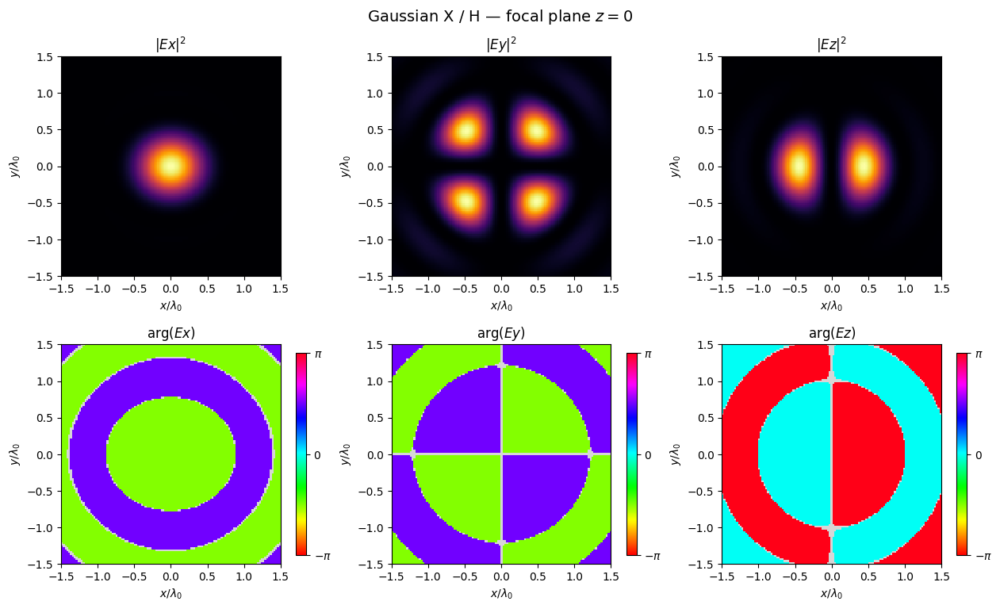

Peak |E|²: 2.09481; longitudinal share: 0.1312


In [8]:
# Compute the three complex components, then inspect intensity and phase.
E_gauss_1 = calculate(gaussian(JONES["X / H"]))
maps(E_gauss_1, "Gaussian X / H")

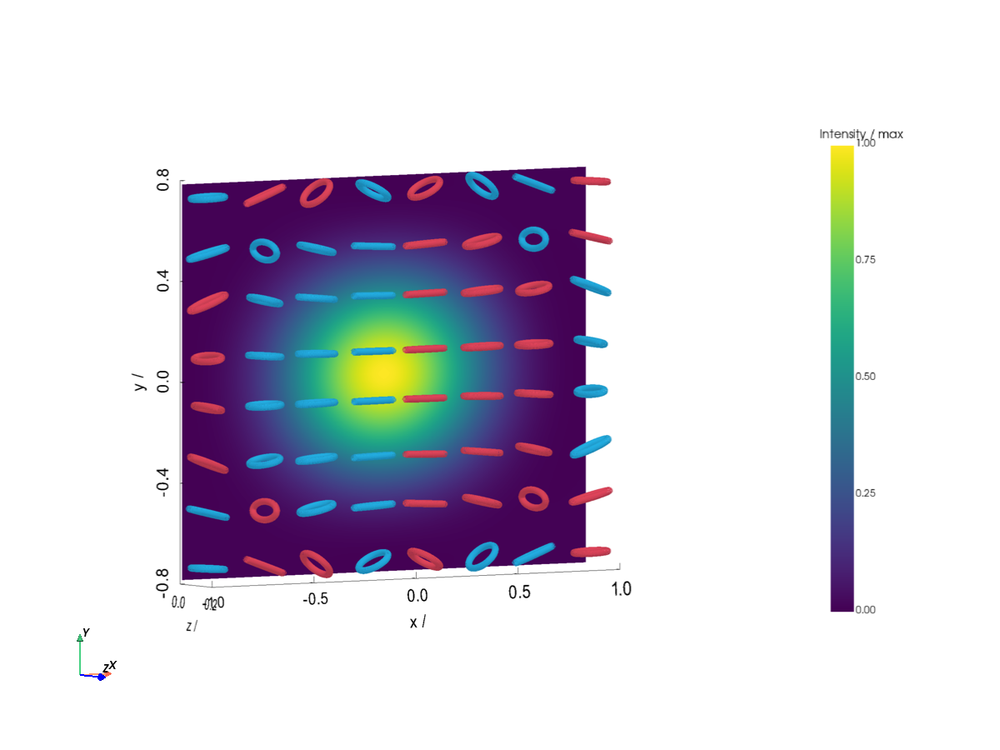

In [9]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_gauss_1, "Gaussian X / H")

### 1.2. Gaussian — Y / V

Compare with H: the ideal circular pupil is rotationally symmetric, so interchanging x and y rotates the corresponding pattern.

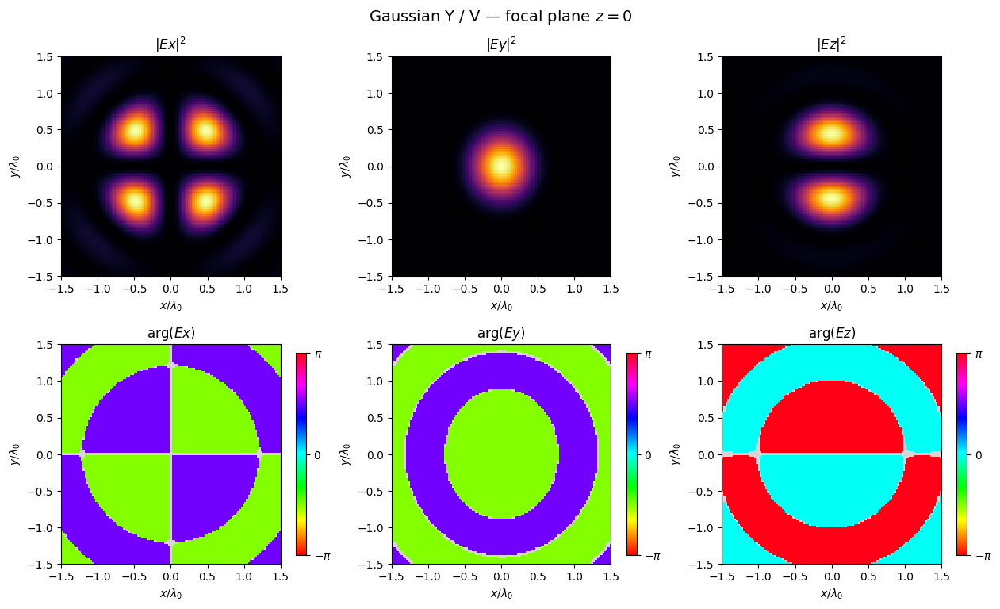

Peak |E|²: 2.09481; longitudinal share: 0.1312


In [10]:
# Compute the three complex components, then inspect intensity and phase.
E_gauss_2 = calculate(gaussian(JONES["Y / V"]))
maps(E_gauss_2, "Gaussian Y / V")

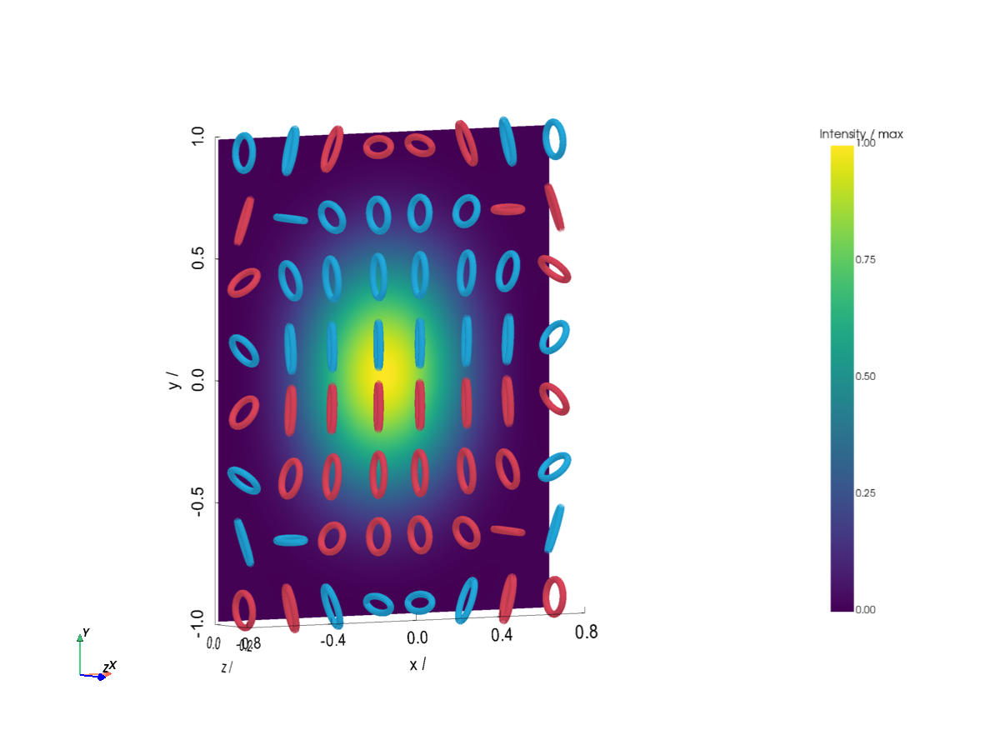

In [11]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_gauss_2, "Gaussian Y / V")

### 1.3. Gaussian — D (+45°)

Observe how a 45° rotation of the incident Jones vector changes the orientation of the longitudinal lobes.

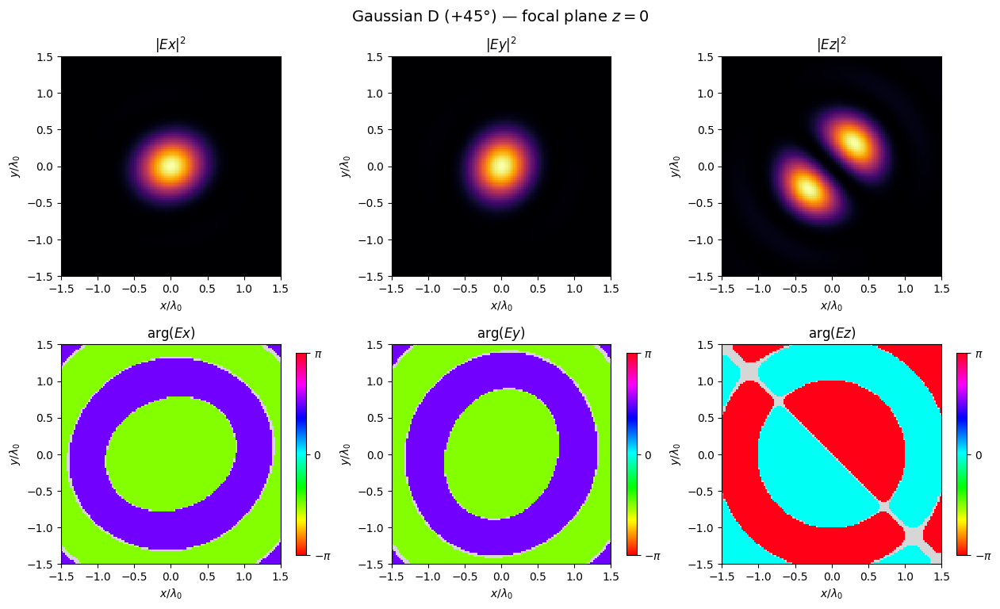

Peak |E|²: 2.09481; longitudinal share: 0.1312


In [12]:
# Compute the three complex components, then inspect intensity and phase.
E_gauss_3 = calculate(gaussian(JONES["D (+45°)"]))
maps(E_gauss_3, "Gaussian D (+45°)")

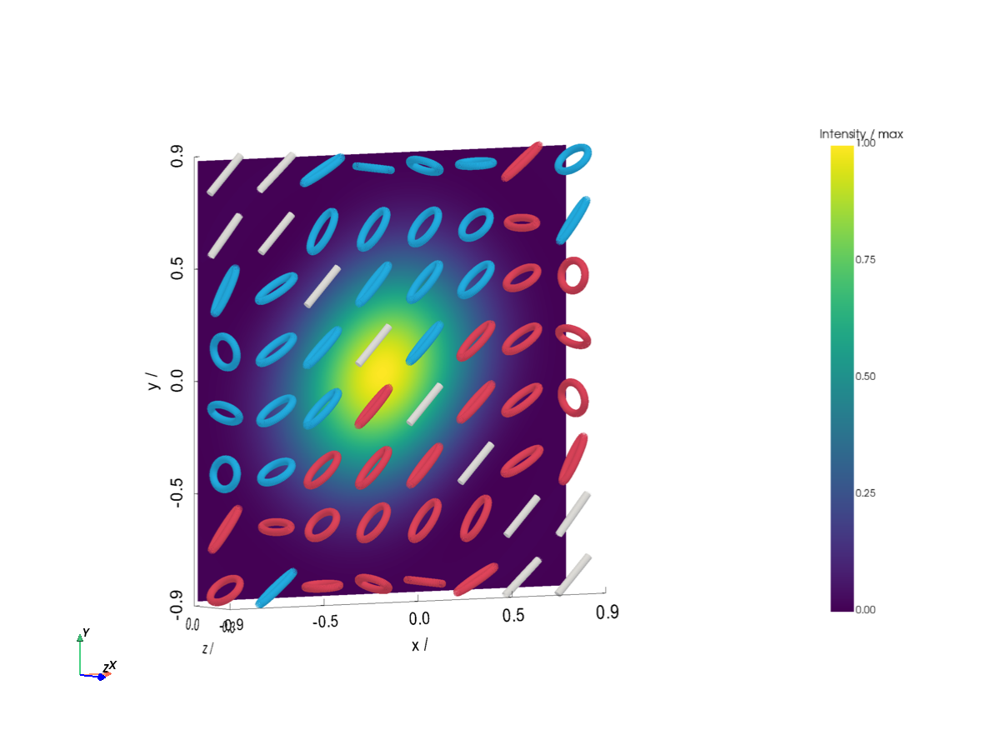

In [13]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_gauss_3, "Gaussian D (+45°)")

### 1.4. Gaussian — A (-45°)

Compare with D to see the effect of reversing the relative sign of the two transverse amplitudes.

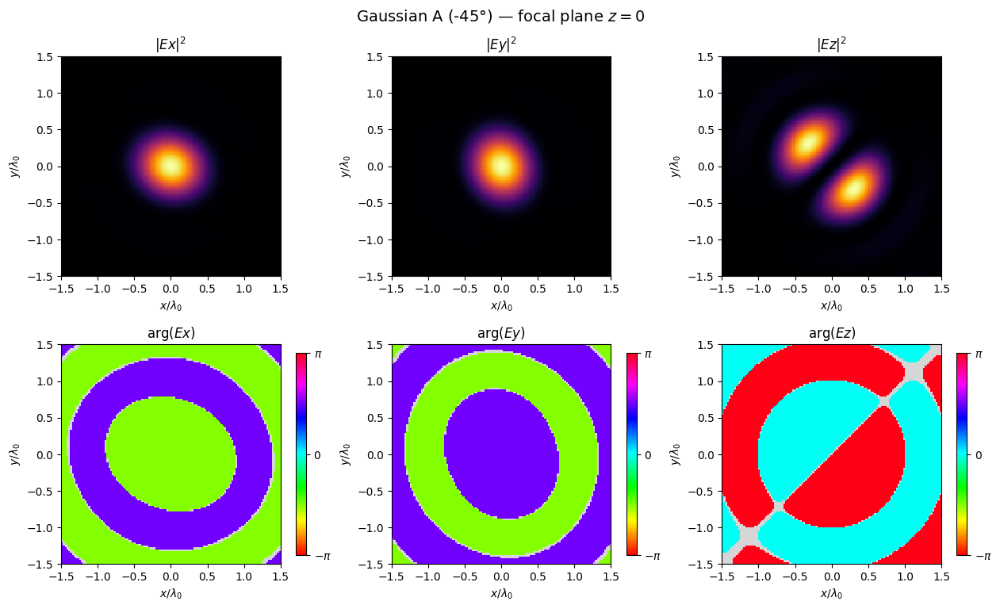

Peak |E|²: 2.09481; longitudinal share: 0.1312


In [14]:
# Compute the three complex components, then inspect intensity and phase.
E_gauss_4 = calculate(gaussian(JONES["A (-45°)"]))
maps(E_gauss_4, "Gaussian A (-45°)")

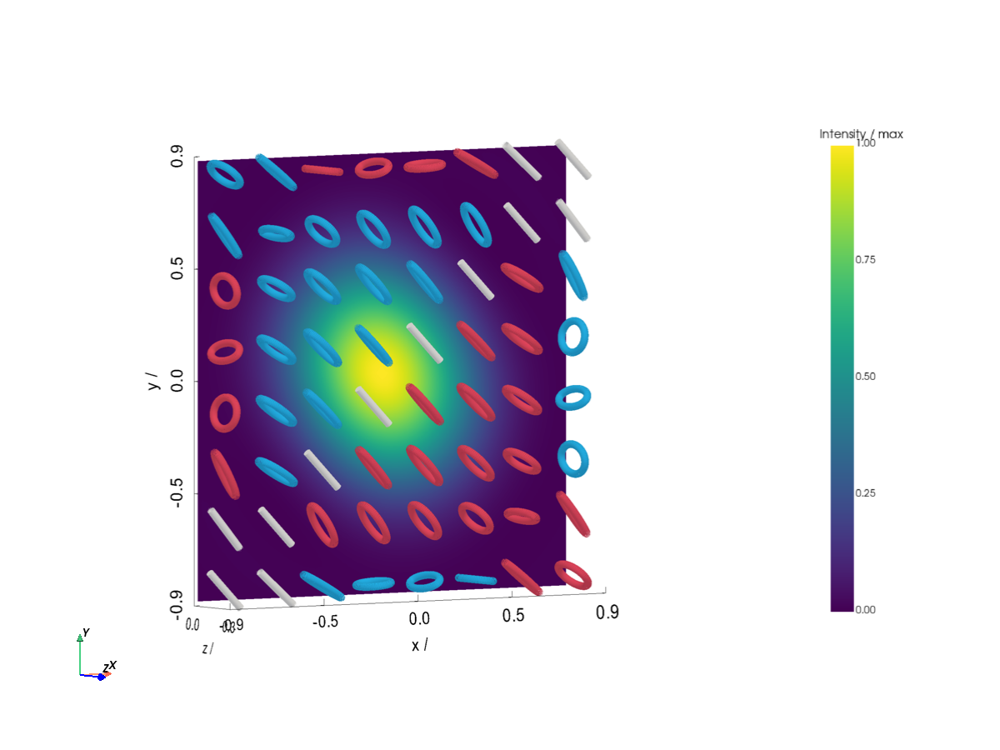

In [15]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_gauss_4, "Gaussian A (-45°)")

### 1.5. Gaussian — R

Examine how the relative phase of the transverse components and the longitudinal field generate spatially varying three-dimensional ellipses.

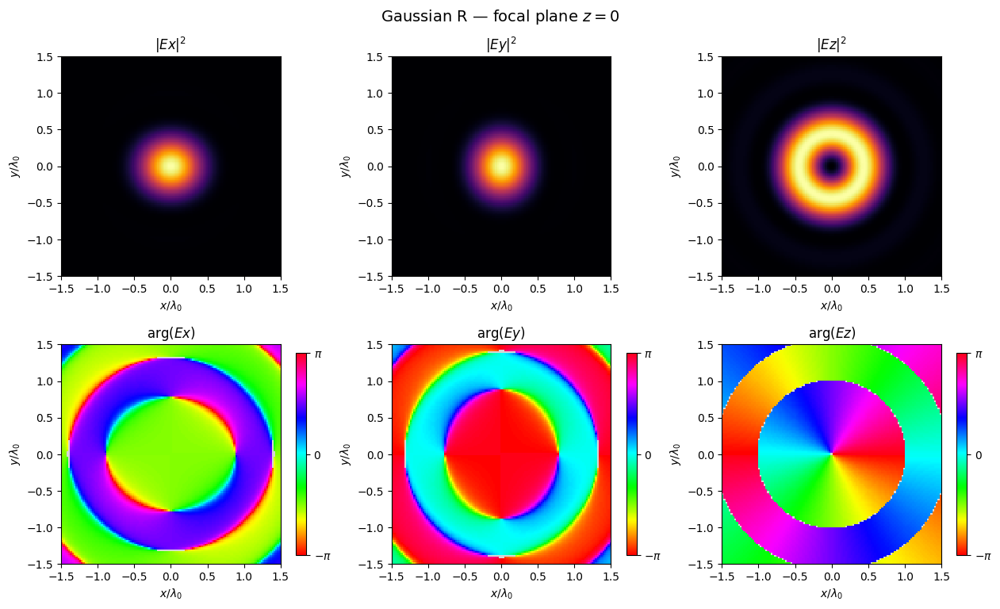

Peak |E|²: 2.09481; longitudinal share: 0.1312


In [16]:
# Compute the three complex components, then inspect intensity and phase.
E_gauss_5 = calculate(gaussian(JONES["R"]))
maps(E_gauss_5, "Gaussian R")

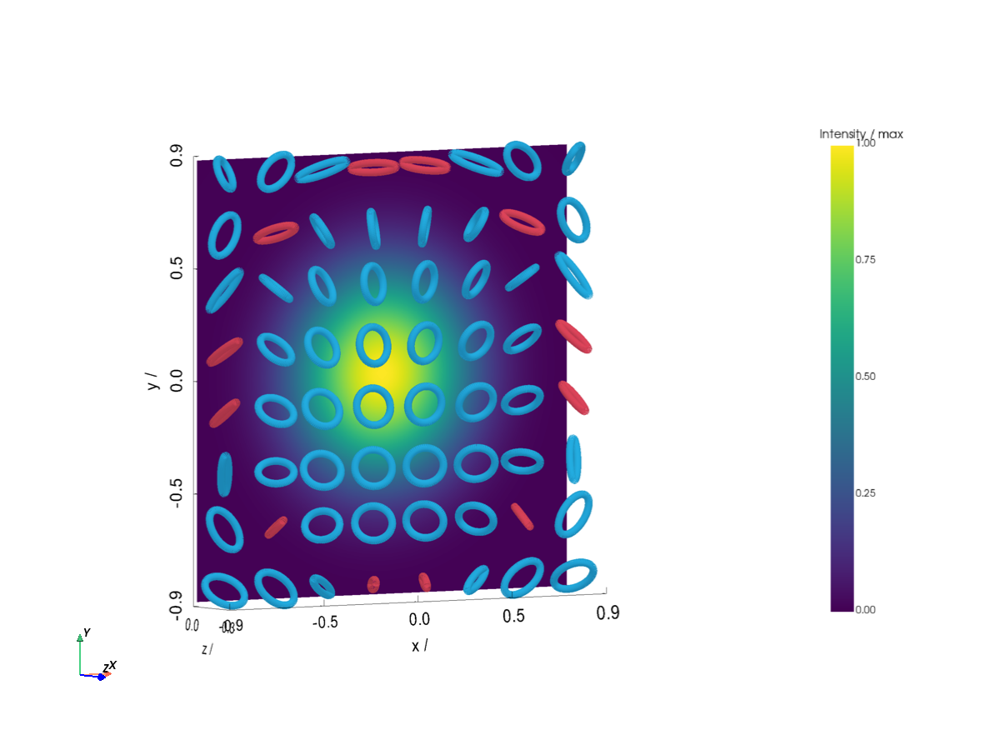

In [17]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_gauss_5, "Gaussian R")

### 1.6. Gaussian — L

Compare the opposite circular state with R, paying attention to the component phases and signed spin convention.

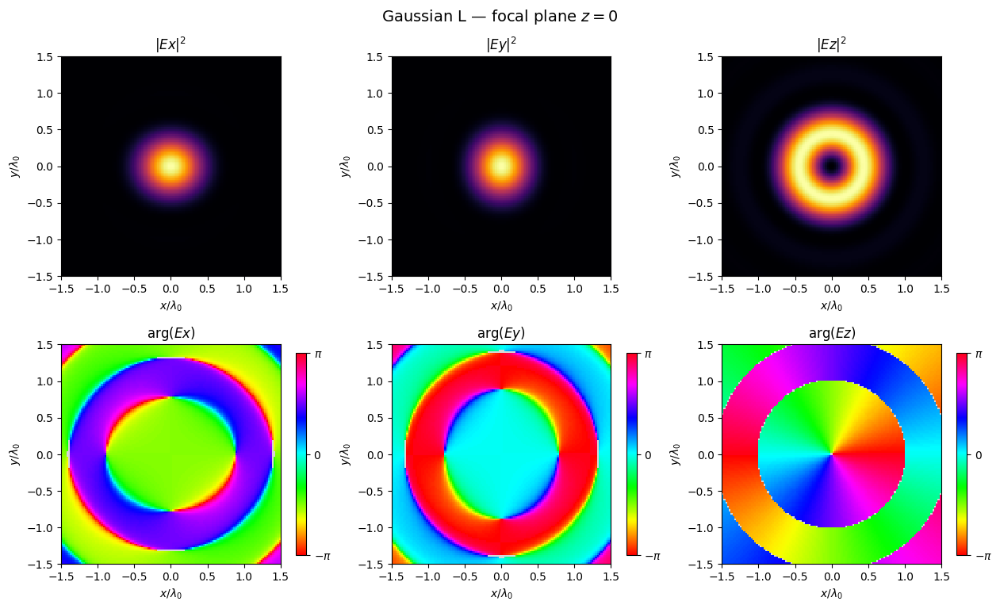

Peak |E|²: 2.09481; longitudinal share: 0.1312


In [18]:
# Compute the three complex components, then inspect intensity and phase.
E_gauss_6 = calculate(gaussian(JONES["L"]))
maps(E_gauss_6, "Gaussian L")

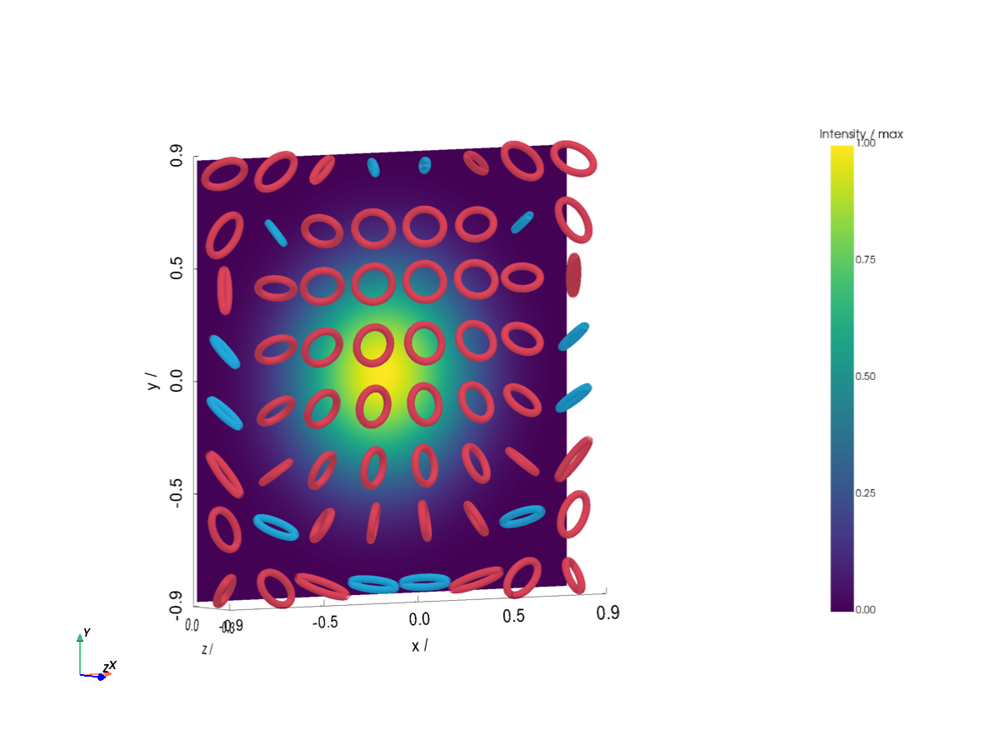

In [19]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_gauss_6, "Gaussian L")

## 2. Laguerre–Gaussian vortex beams

For $|\ell|=1$, the incident scalar pupil has a phase winding $e^{i\ell\phi}$ and an on-axis amplitude zero. The vectorial lens transformation couples this azimuthal order to $\ell\pm1$ in the longitudinal field and $\ell\pm2$ in the transverse field. This makes phase maps especially informative: an incident vortex does not require every focused component to vanish on-axis.

### 2.1. Positive charge ($LG_0^{+1}$)

Calculate the six uniform Jones states for $\ell=+1$. Compare linear and circular input, especially the longitudinal on-axis selection rule.

#### LG charge 1, polarization X / H

Use a uniform linear Jones state. Inspect the longitudinal component and the phase winding of each Cartesian field.

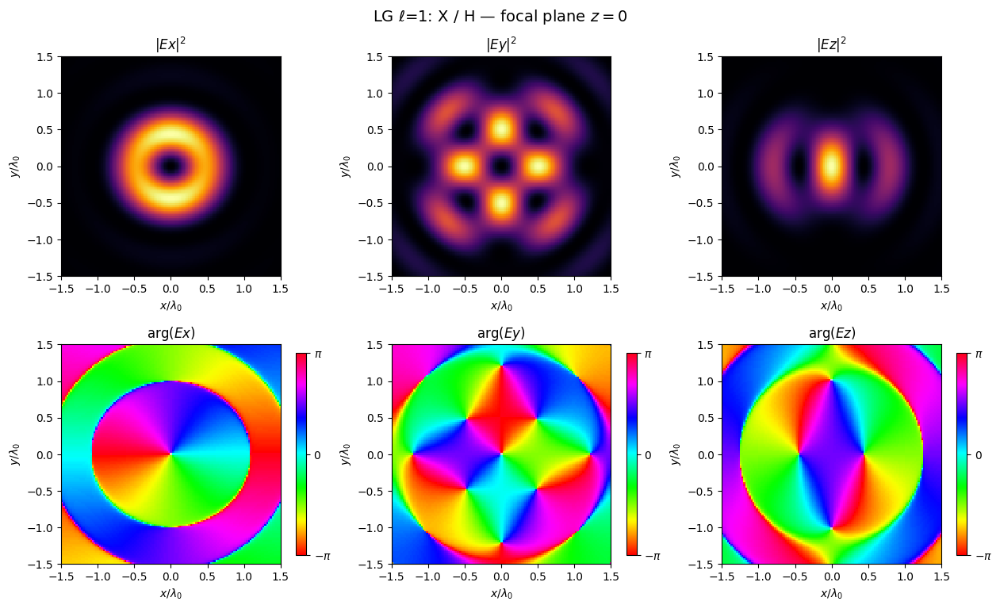

Peak |E|²: 0.273687; longitudinal share: 0.1963


In [20]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_plus_1 = calculate(lg(1,JONES["X / H"]))
maps(E_lg_plus_1, "LG ℓ=1: X / H")

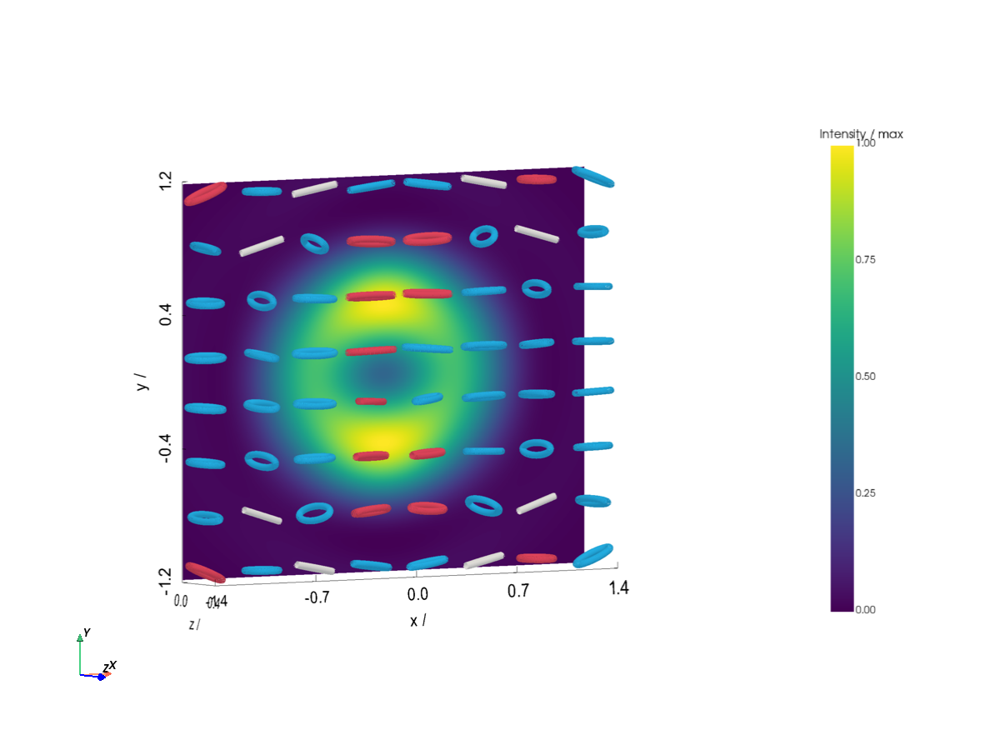

In [21]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_plus_1, "LG ℓ=1: X / H")

#### LG charge 1, polarization Y / V

Use a uniform linear Jones state. Inspect the longitudinal component and the phase winding of each Cartesian field.

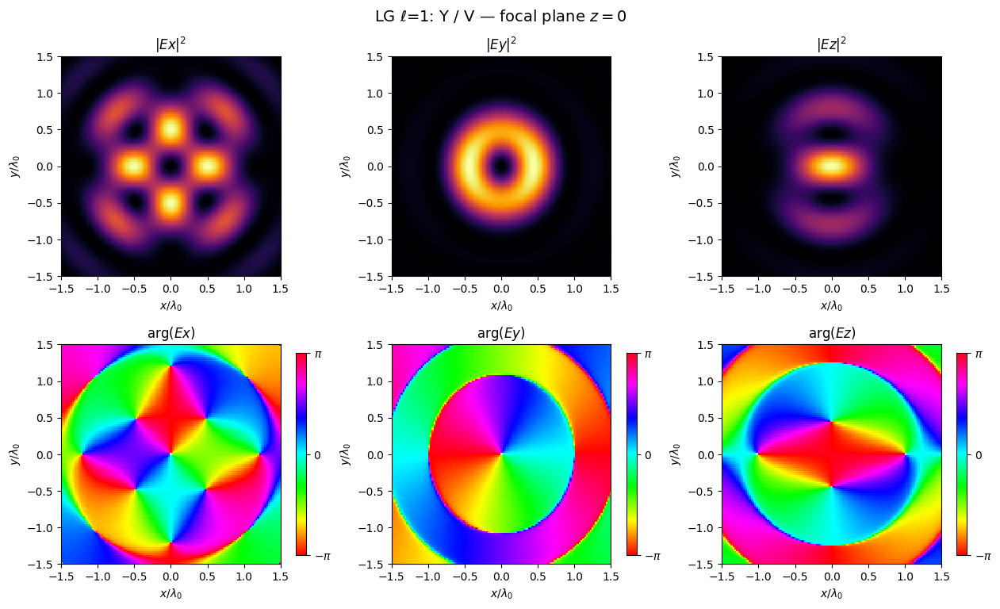

Peak |E|²: 0.273687; longitudinal share: 0.1963


In [22]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_plus_2 = calculate(lg(1,JONES["Y / V"]))
maps(E_lg_plus_2, "LG ℓ=1: Y / V")

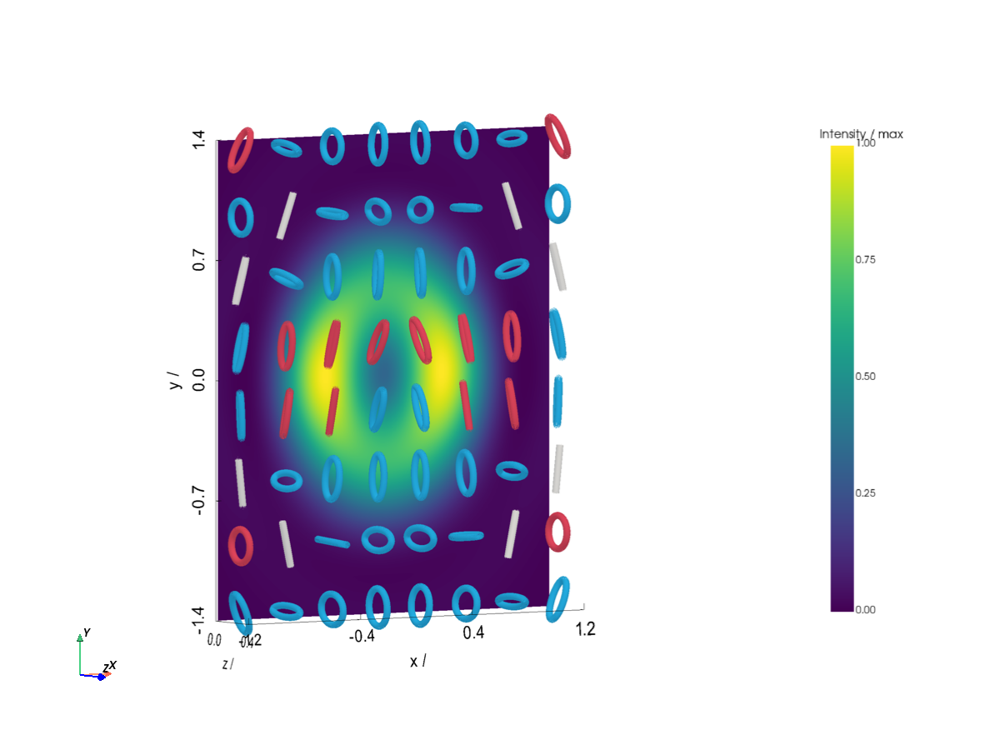

In [23]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_plus_2, "LG ℓ=1: Y / V")

#### LG charge 1, polarization D (+45°)

Use a uniform linear Jones state. Inspect the longitudinal component and the phase winding of each Cartesian field.

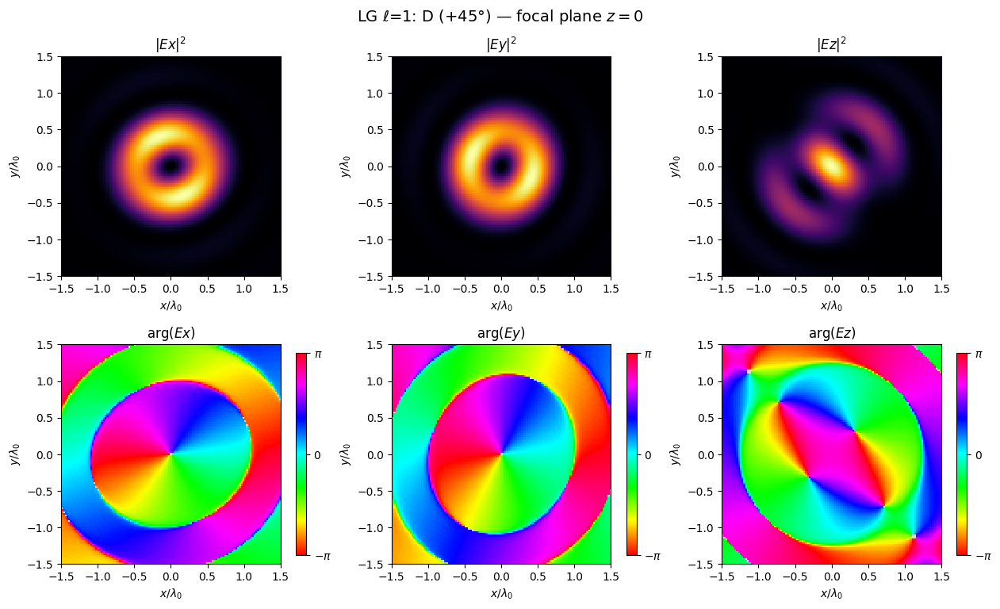

Peak |E|²: 0.27387; longitudinal share: 0.1963


In [24]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_plus_3 = calculate(lg(1,JONES["D (+45°)"]))
maps(E_lg_plus_3, "LG ℓ=1: D (+45°)")

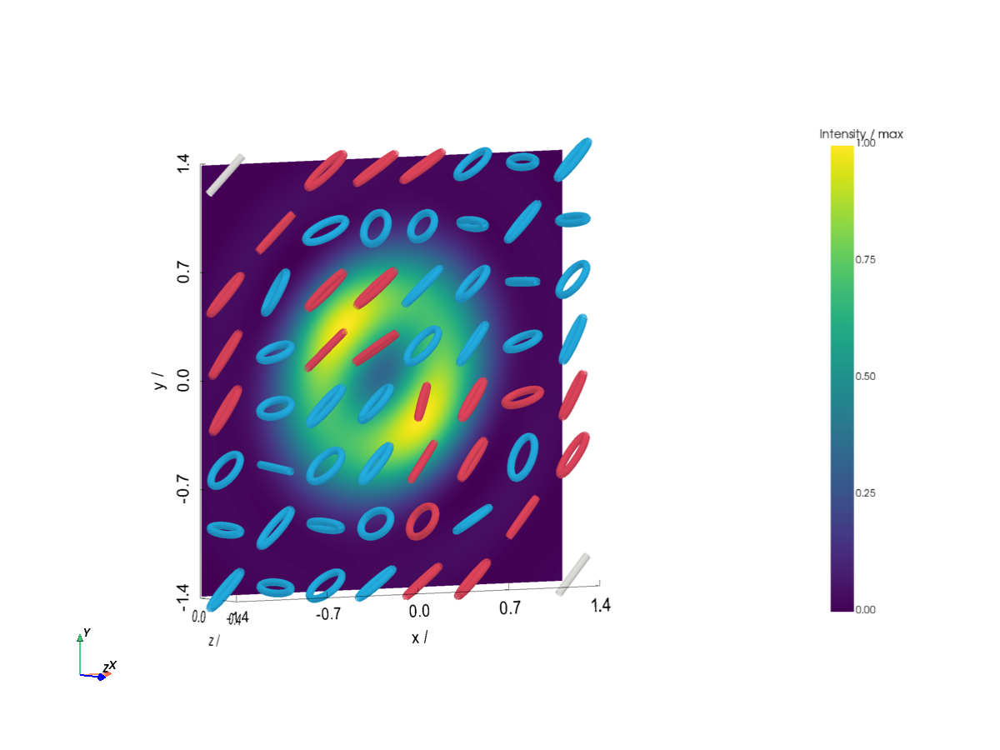

In [25]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_plus_3, "LG ℓ=1: D (+45°)")

#### LG charge 1, polarization A (-45°)

Use a uniform linear Jones state. Inspect the longitudinal component and the phase winding of each Cartesian field.

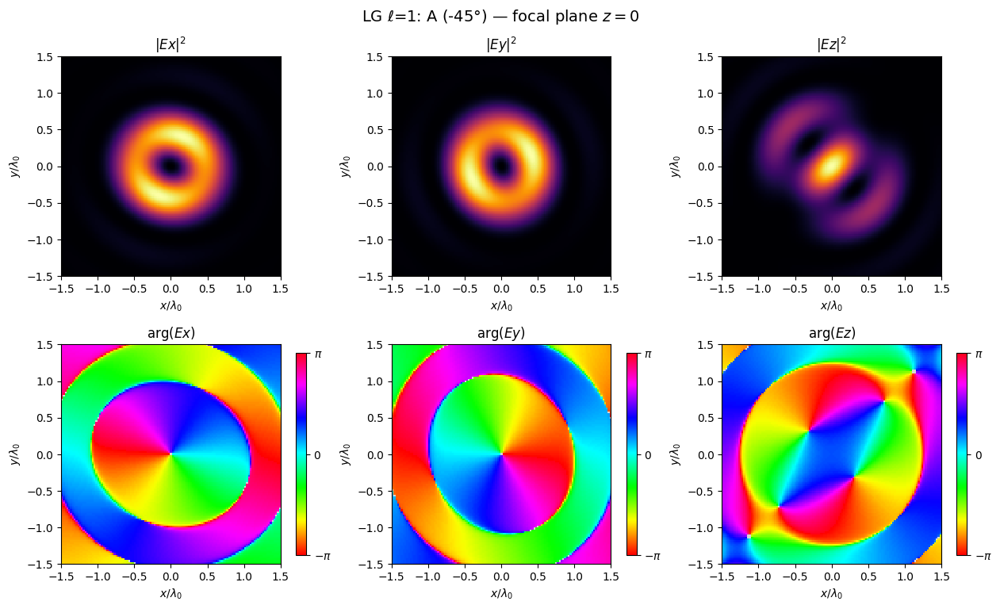

Peak |E|²: 0.27387; longitudinal share: 0.1963


In [26]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_plus_4 = calculate(lg(1,JONES["A (-45°)"]))
maps(E_lg_plus_4, "LG ℓ=1: A (-45°)")

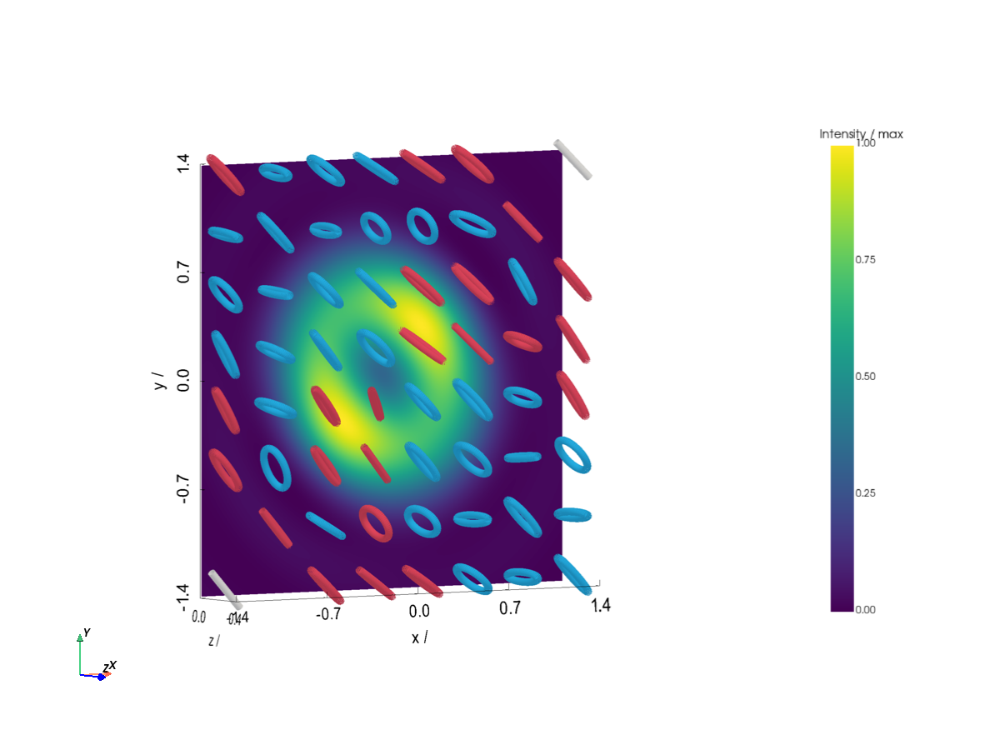

In [27]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_plus_4, "LG ℓ=1: A (-45°)")

#### LG charge 1, polarization R

Use a uniform circular Jones state. Compare the on-axis longitudinal response with the opposite circular input at the same charge.

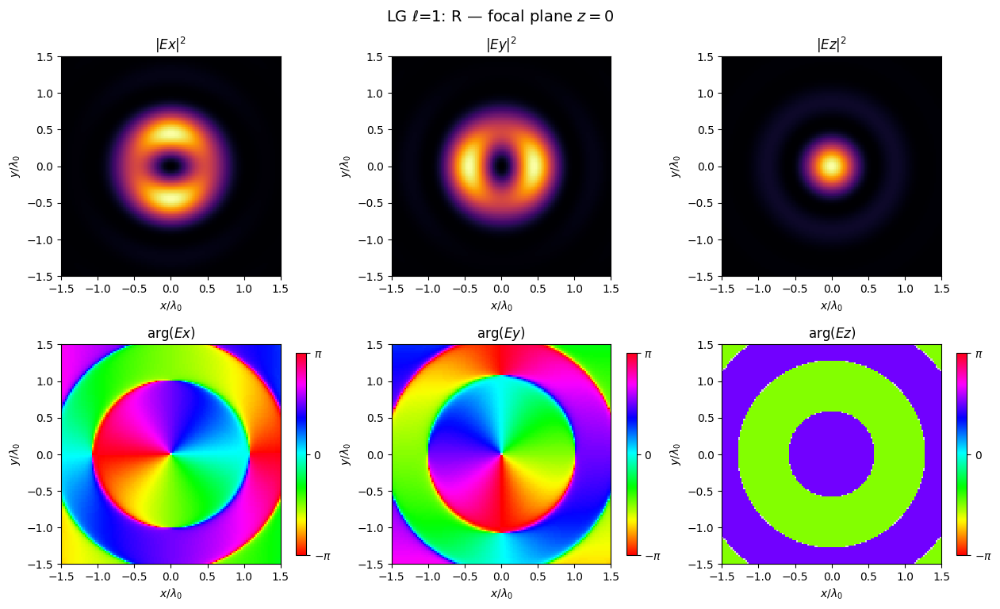

Peak |E|²: 0.242068; longitudinal share: 0.1965


In [28]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_plus_5 = calculate(lg(1,JONES["R"]))
maps(E_lg_plus_5, "LG ℓ=1: R")

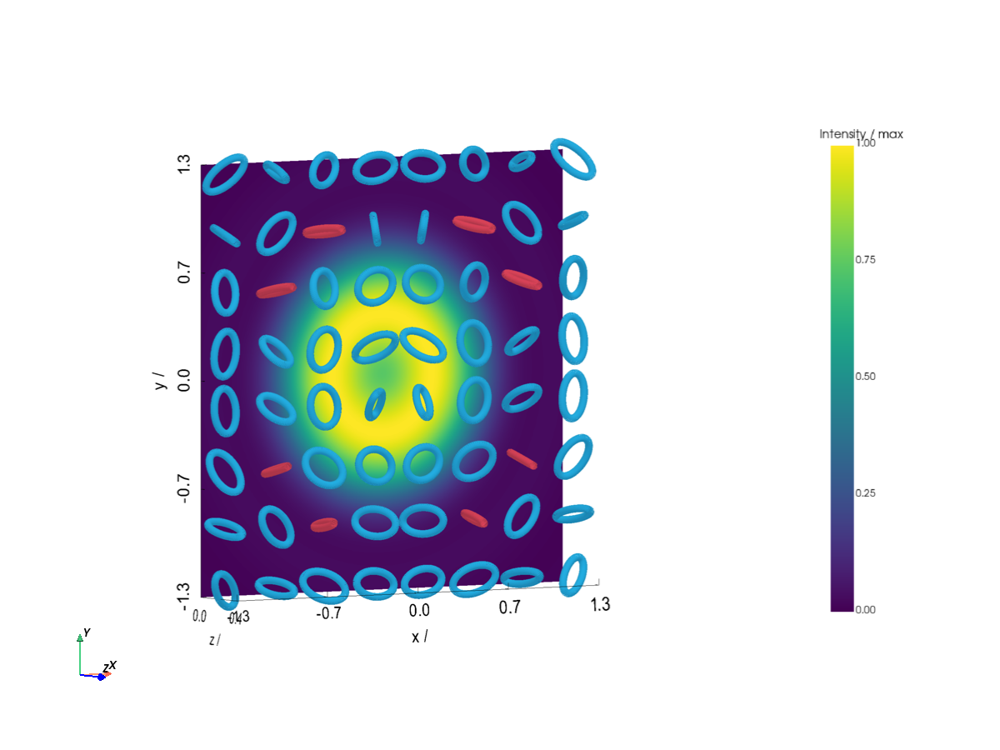

In [29]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_plus_5, "LG ℓ=1: R")

#### LG charge 1, polarization L

Use a uniform circular Jones state. Compare the on-axis longitudinal response with the opposite circular input at the same charge.

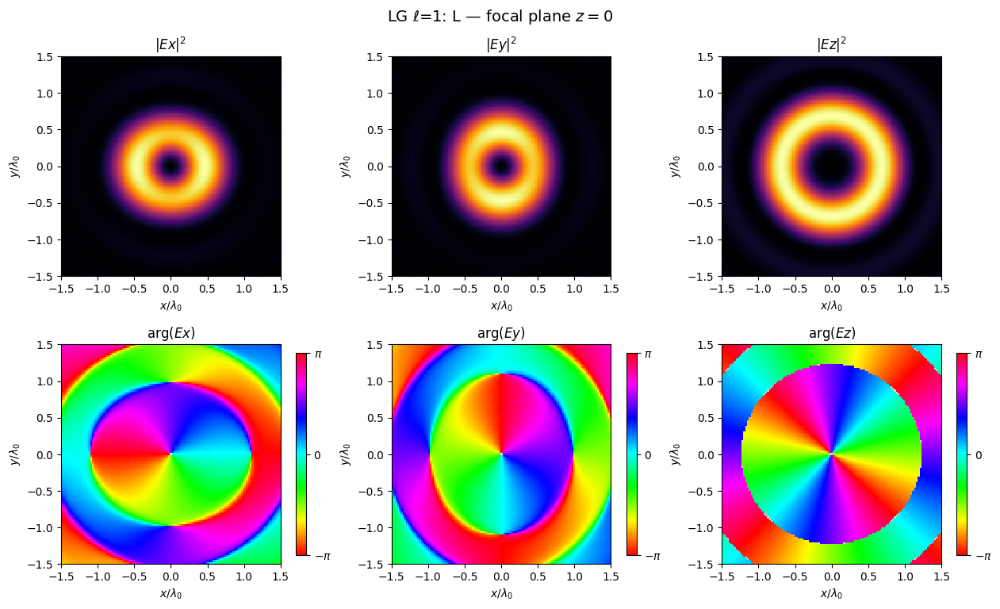

Peak |E|²: 0.230931; longitudinal share: 0.1962


In [30]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_plus_6 = calculate(lg(1,JONES["L"]))
maps(E_lg_plus_6, "LG ℓ=1: L")

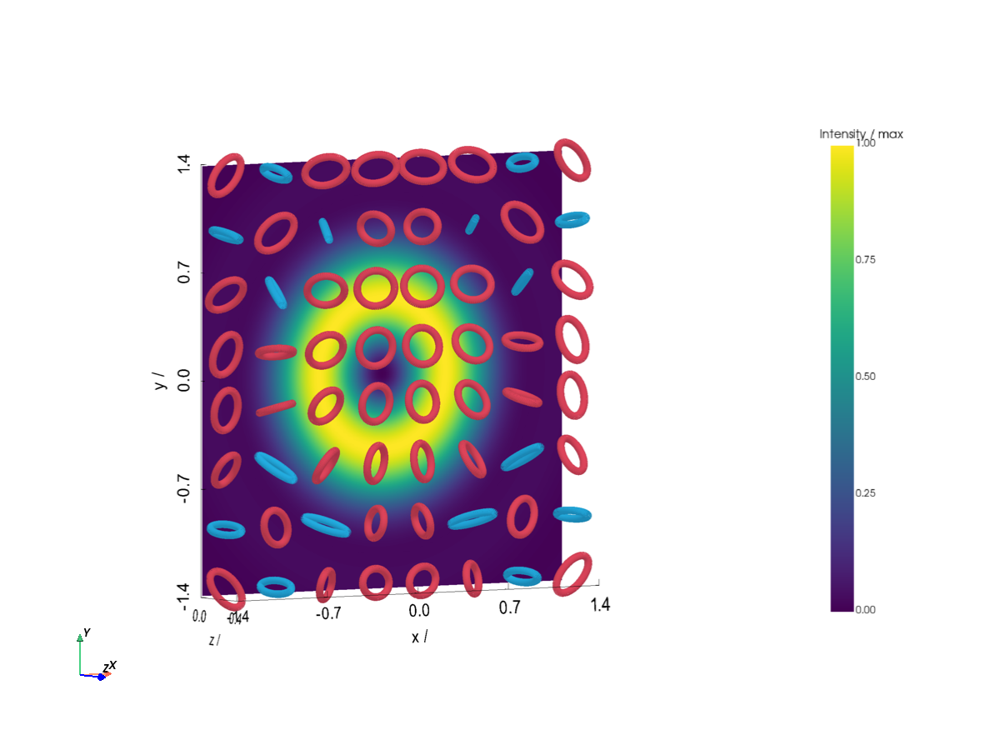

In [31]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_plus_6, "LG ℓ=1: L")

### 2.2. Negative charge ($LG_0^{-1}$)

Reverse the incident phase winding while preserving the same radial envelope. Compare with the positive-charge family, including the interchange of circular-state selection rules. The relative sign between orbital charge and circular polarization determines which azimuthal orders appear in the focused field.

#### LG charge -1, polarization X / H

Use a uniform linear Jones state. Inspect the longitudinal component and the phase winding of each Cartesian field.

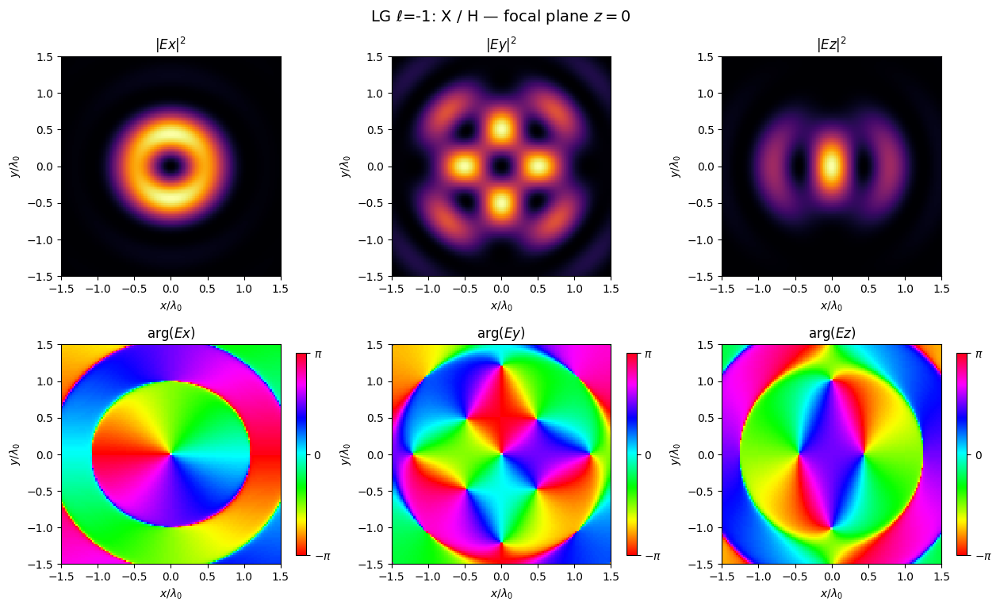

Peak |E|²: 0.273687; longitudinal share: 0.1963


In [32]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_minus_1 = calculate(lg(-1,JONES["X / H"]))
maps(E_lg_minus_1, "LG ℓ=-1: X / H")

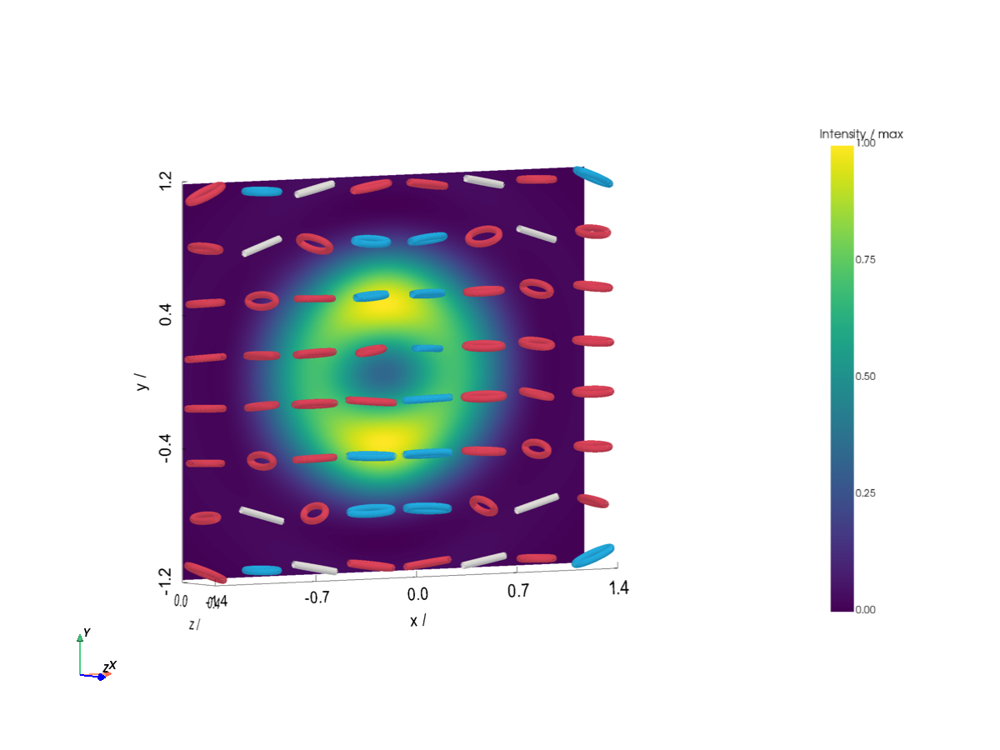

In [33]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_minus_1, "LG ℓ=-1: X / H")

#### LG charge -1, polarization Y / V

Use a uniform linear Jones state. Inspect the longitudinal component and the phase winding of each Cartesian field.

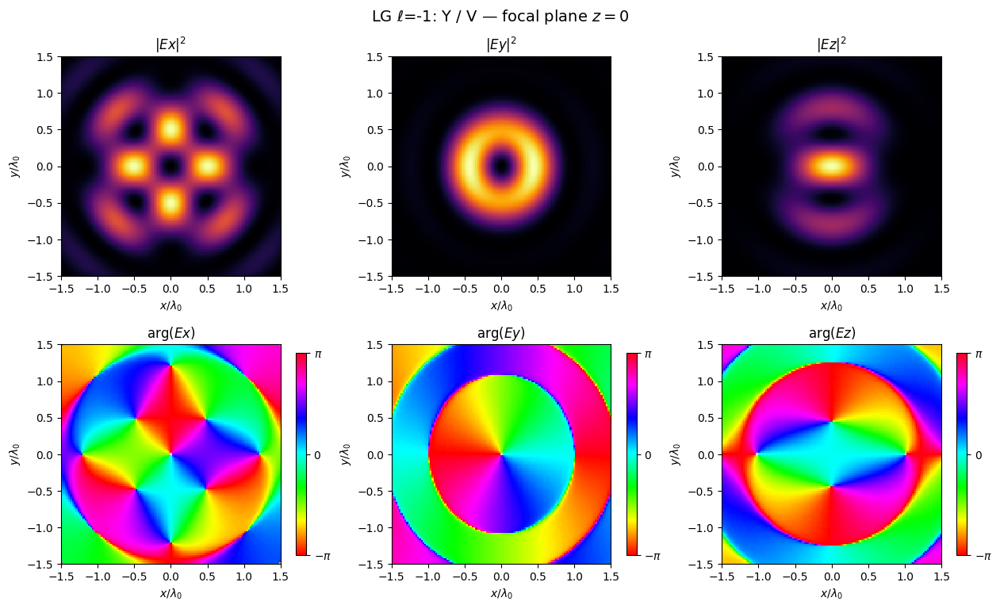

Peak |E|²: 0.273687; longitudinal share: 0.1963


In [34]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_minus_2 = calculate(lg(-1,JONES["Y / V"]))
maps(E_lg_minus_2, "LG ℓ=-1: Y / V")

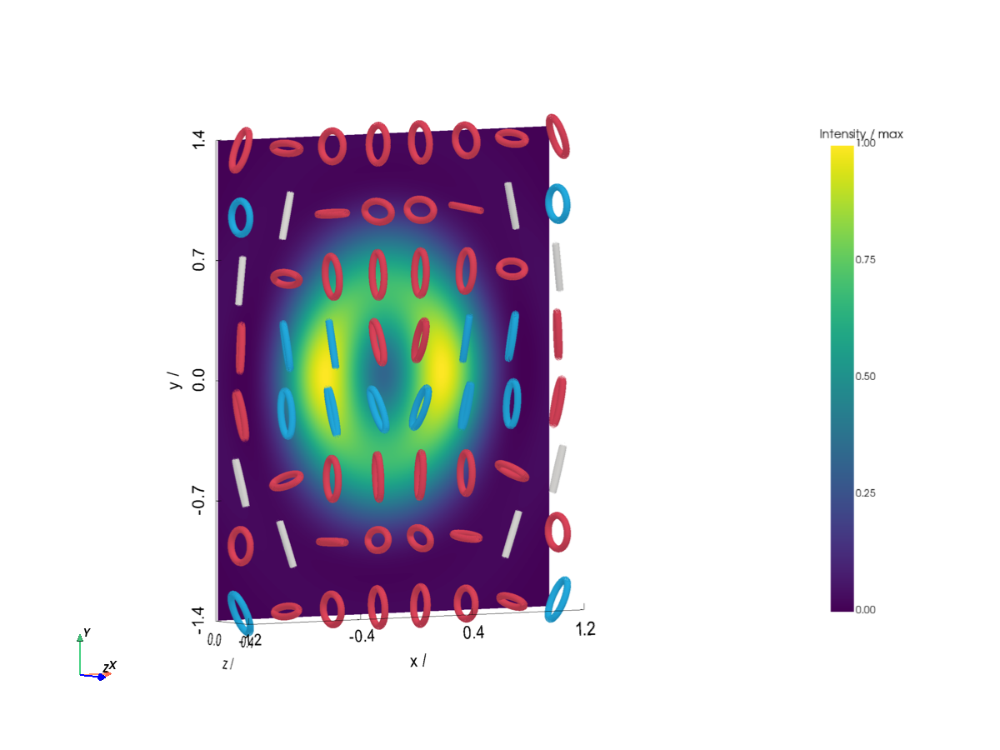

In [35]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_minus_2, "LG ℓ=-1: Y / V")

#### LG charge -1, polarization D (+45°)

Use a uniform linear Jones state. Inspect the longitudinal component and the phase winding of each Cartesian field.

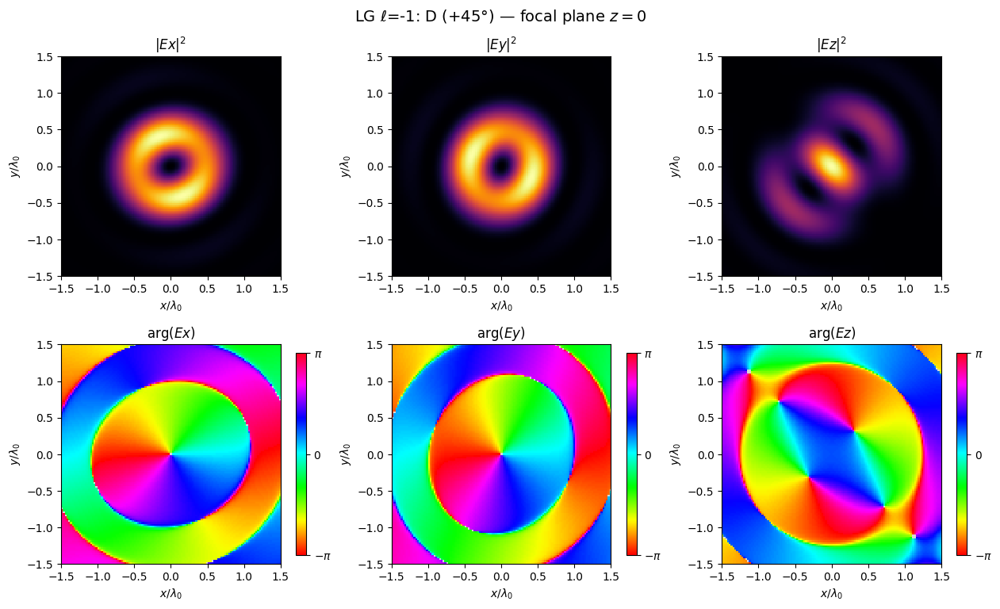

Peak |E|²: 0.27387; longitudinal share: 0.1963


In [36]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_minus_3 = calculate(lg(-1,JONES["D (+45°)"]))
maps(E_lg_minus_3, "LG ℓ=-1: D (+45°)")

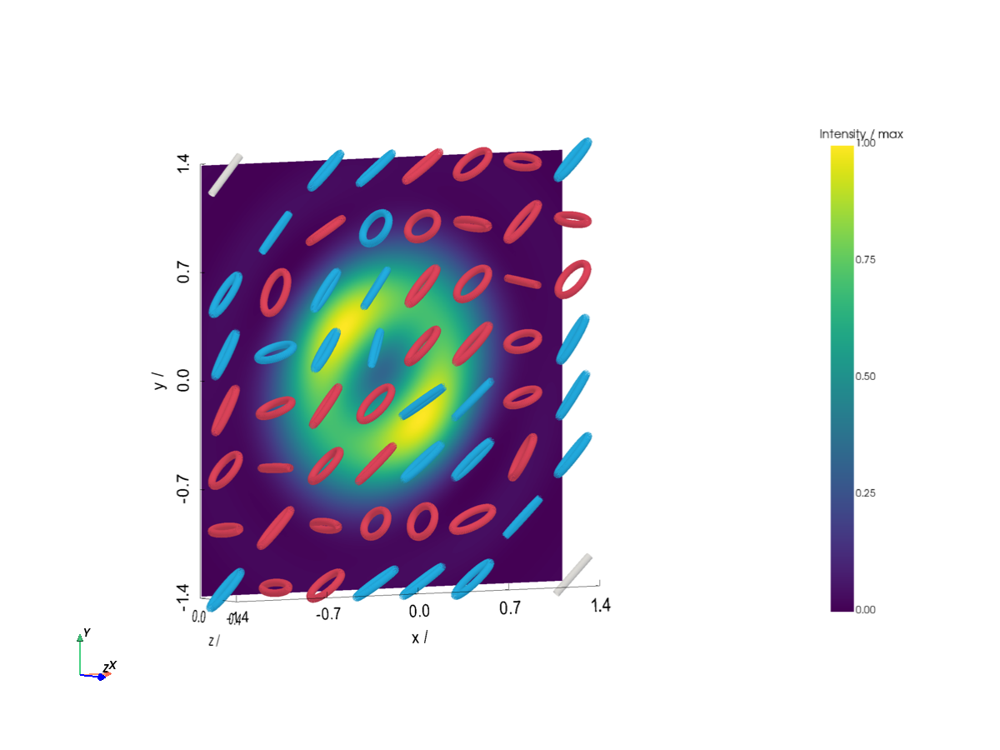

In [37]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_minus_3, "LG ℓ=-1: D (+45°)")

#### LG charge -1, polarization A (-45°)

Use a uniform linear Jones state. Inspect the longitudinal component and the phase winding of each Cartesian field.

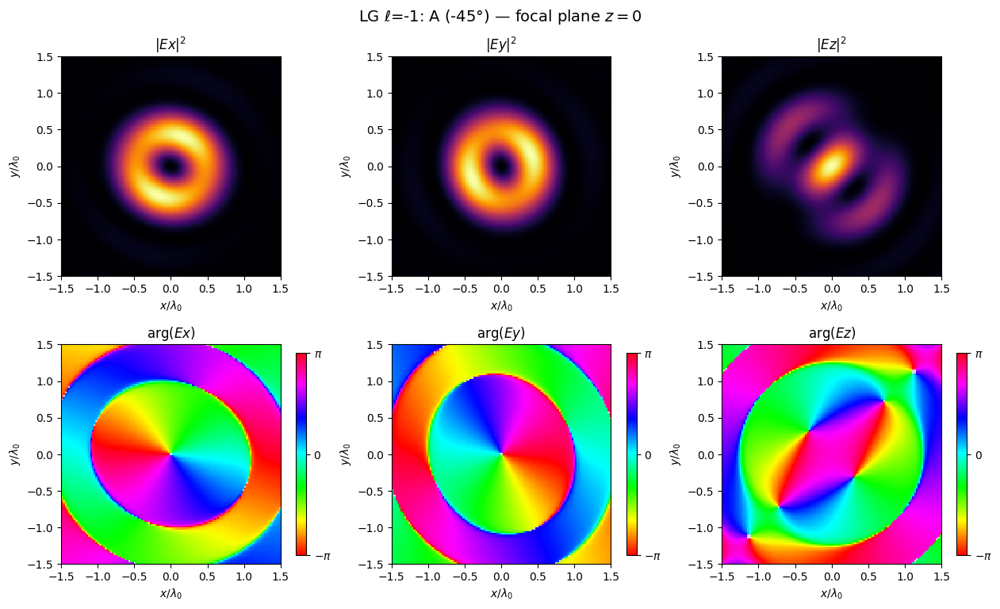

Peak |E|²: 0.27387; longitudinal share: 0.1963


In [38]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_minus_4 = calculate(lg(-1,JONES["A (-45°)"]))
maps(E_lg_minus_4, "LG ℓ=-1: A (-45°)")

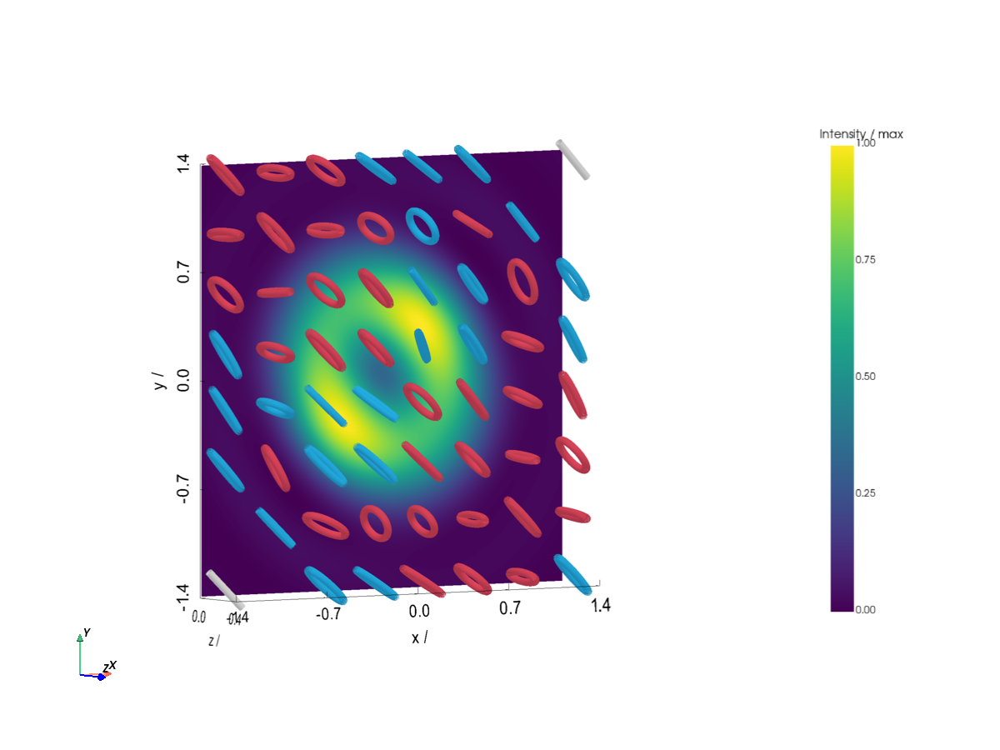

In [39]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_minus_4, "LG ℓ=-1: A (-45°)")

#### LG charge -1, polarization R

Use a uniform circular Jones state. Compare the on-axis longitudinal response with the opposite circular input at the same charge.

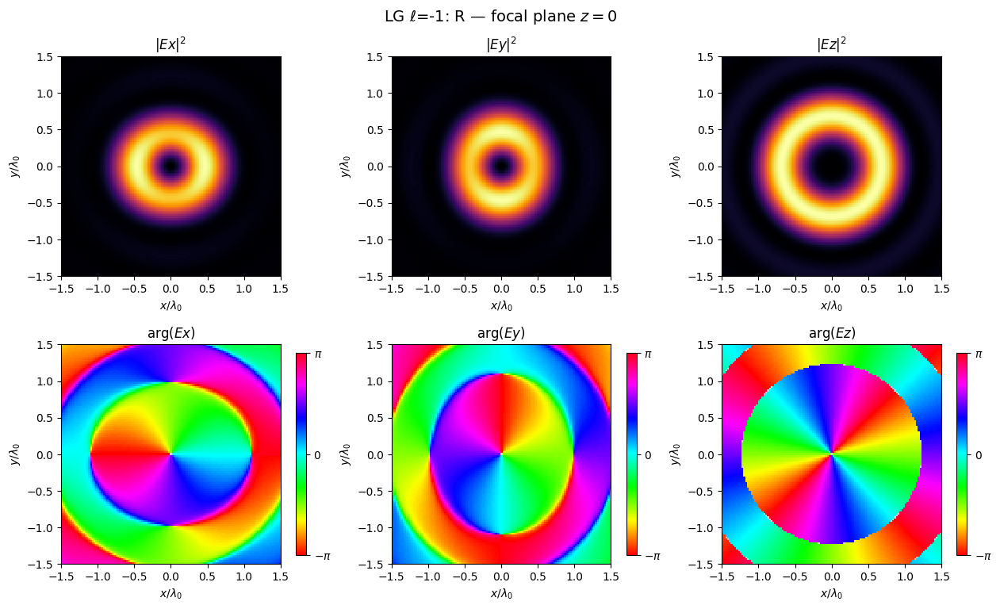

Peak |E|²: 0.230931; longitudinal share: 0.1962


In [40]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_minus_5 = calculate(lg(-1,JONES["R"]))
maps(E_lg_minus_5, "LG ℓ=-1: R")

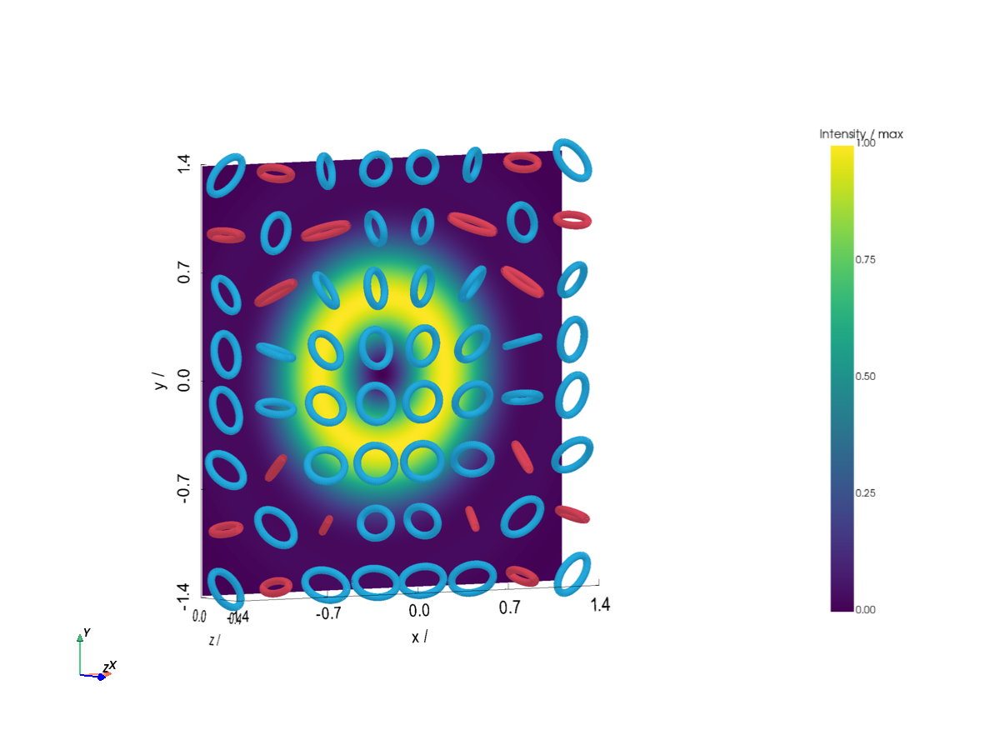

In [41]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_minus_5, "LG ℓ=-1: R")

#### LG charge -1, polarization L

Use a uniform circular Jones state. Compare the on-axis longitudinal response with the opposite circular input at the same charge.

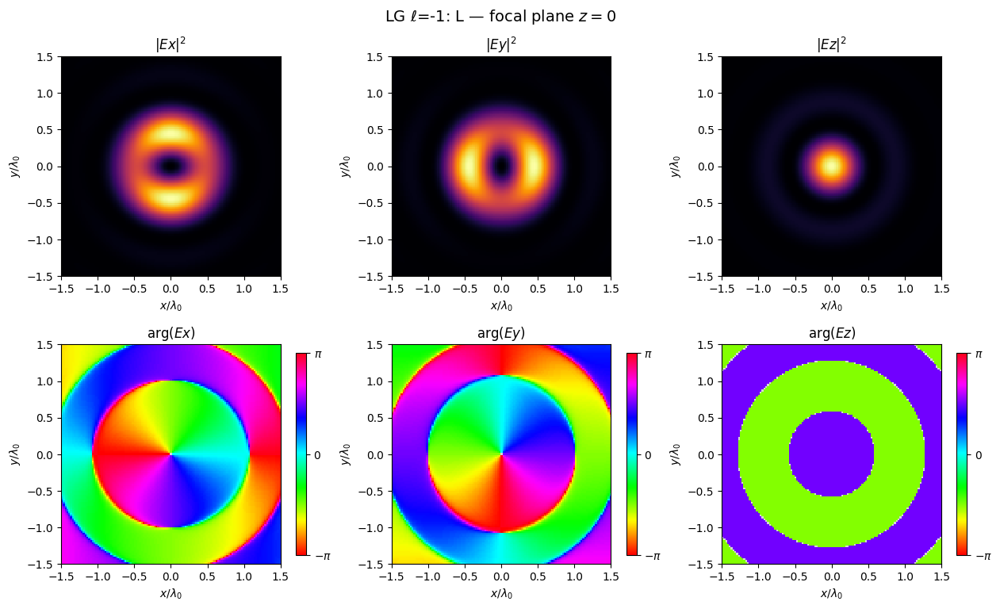

Peak |E|²: 0.242068; longitudinal share: 0.1965


In [42]:
# Compute the three complex components, then inspect intensity and phase.
E_lg_minus_6 = calculate(lg(-1,JONES["L"]))
maps(E_lg_minus_6, "LG ℓ=-1: L")

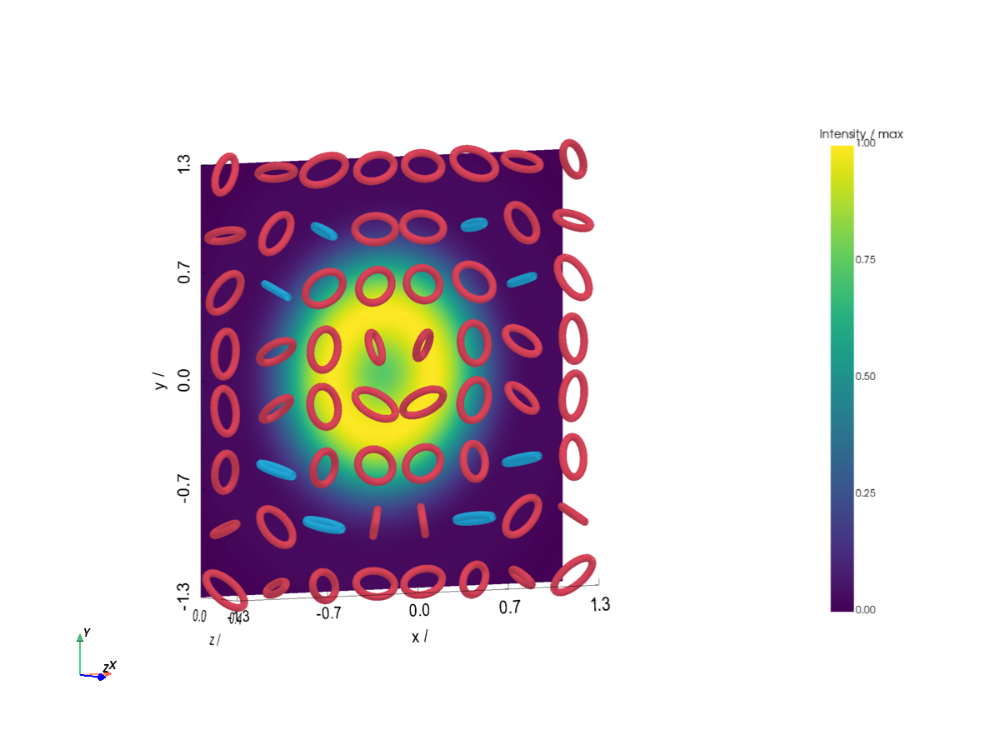

In [43]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_lg_minus_6, "LG ℓ=-1: L")

## 3. Cylindrical-vector beams

These beams have spatially varying transverse linear polarization at the pupil. Let $U_\pm=U_{\pm1}$, and use the explicit circular vectors of Section B.2. The code constructs:

$$
\begin{aligned}
\mathbf E_{\rm rad}&=(U_+\mathbf e_R+U_-\mathbf e_L)/\sqrt2,\\
\mathbf E_{\rm azi}&=(U_+\mathbf e_R-U_-\mathbf e_L)/\sqrt2,\\
\mathbf E_{\rm hyp,X}&=(U_-\mathbf e_R+U_+\mathbf e_L)/\sqrt2,\\
\mathbf E_{\rm hyp,Y}&=(U_-\mathbf e_R-U_+\mathbf e_L)/\sqrt2.
\end{aligned}
$$

The azimuthal and hyperbolic-Y forms may differ from real-valued transverse patterns by a constant overall phase. Because each beam is a coherent superposition of LG-like modes, the same solver applies without changes.

### 3.1. Radial

The pupil polarization points radially. The objective rotates it toward the ray's polar direction, producing a substantial longitudinal field, including a nonzero on-axis contribution.

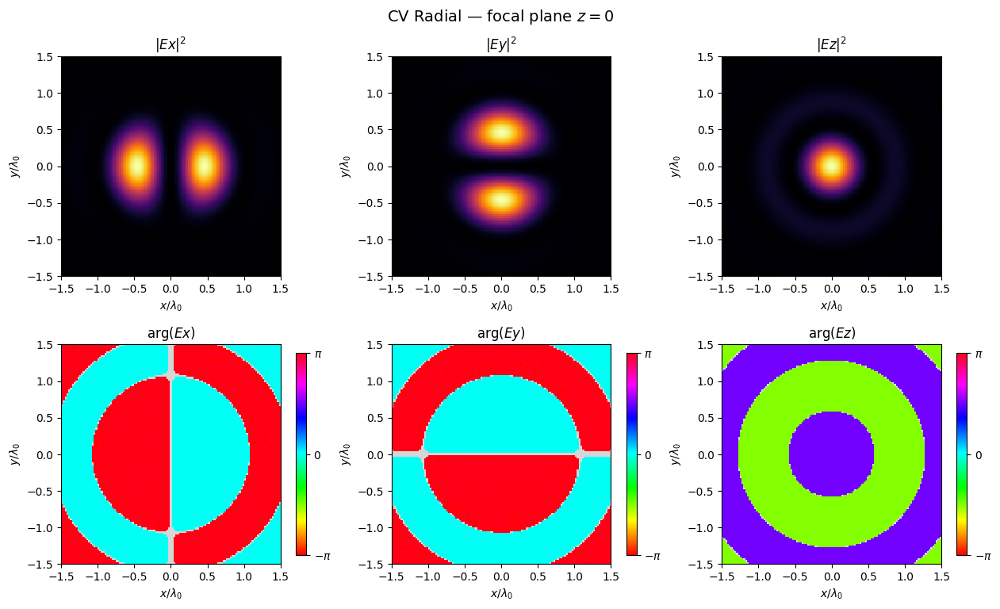

Peak |E|²: 0.358842; longitudinal share: 0.3936


In [44]:
# Compute the three complex components, then inspect intensity and phase.
E_cv_1 = calculate(cylindrical("Radial"))
maps(E_cv_1, "CV Radial")

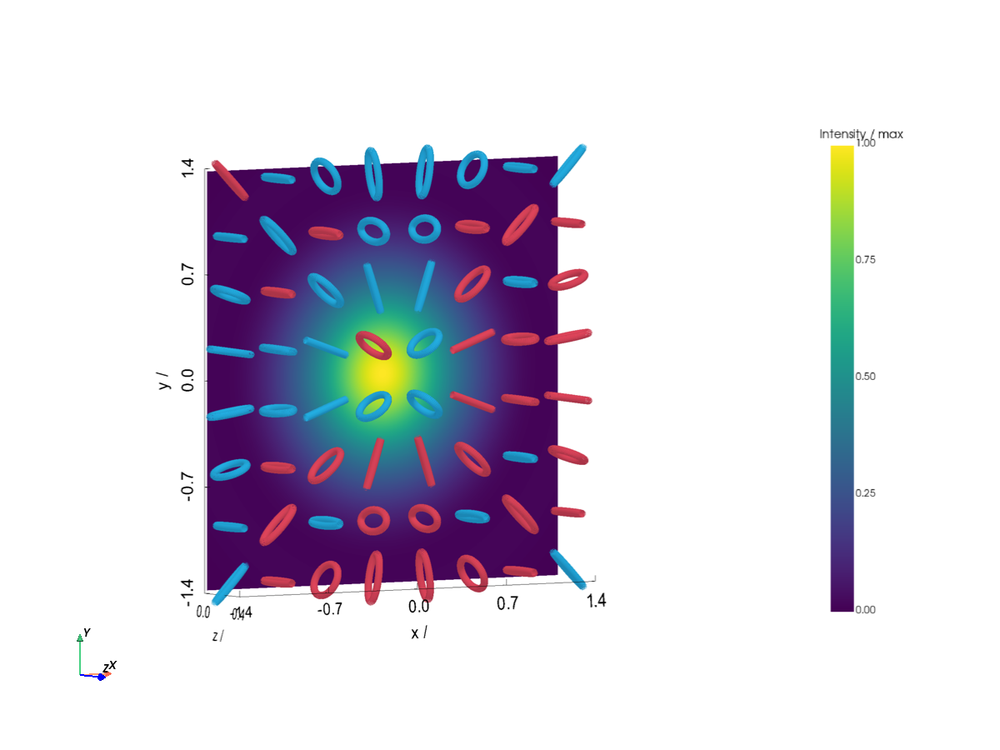

In [45]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_cv_1, "CV Radial")

### 3.2. Azimuthal

The pupil polarization is tangential to circles about the optical axis. For an ideal aplanatic objective it is orthogonal to the radial direction at every pupil point, so the longitudinal field vanishes. This provides a particularly useful numerical check.

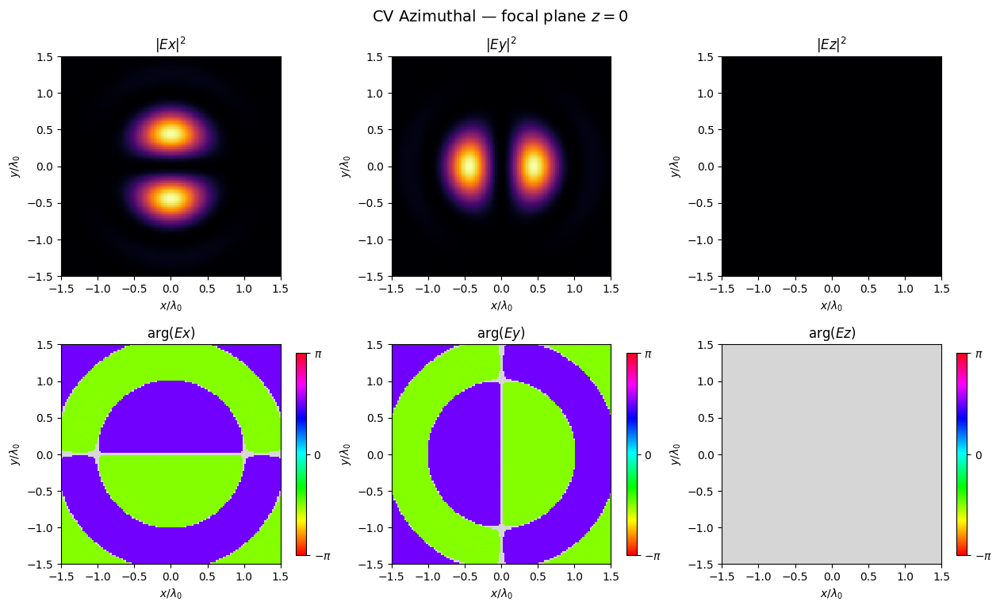

Peak |E|²: 0.274468; longitudinal share: 0.0000


In [46]:
# Compute the three complex components, then inspect intensity and phase.
E_cv_2 = calculate(cylindrical("Azimuthal"))
maps(E_cv_2, "CV Azimuthal")

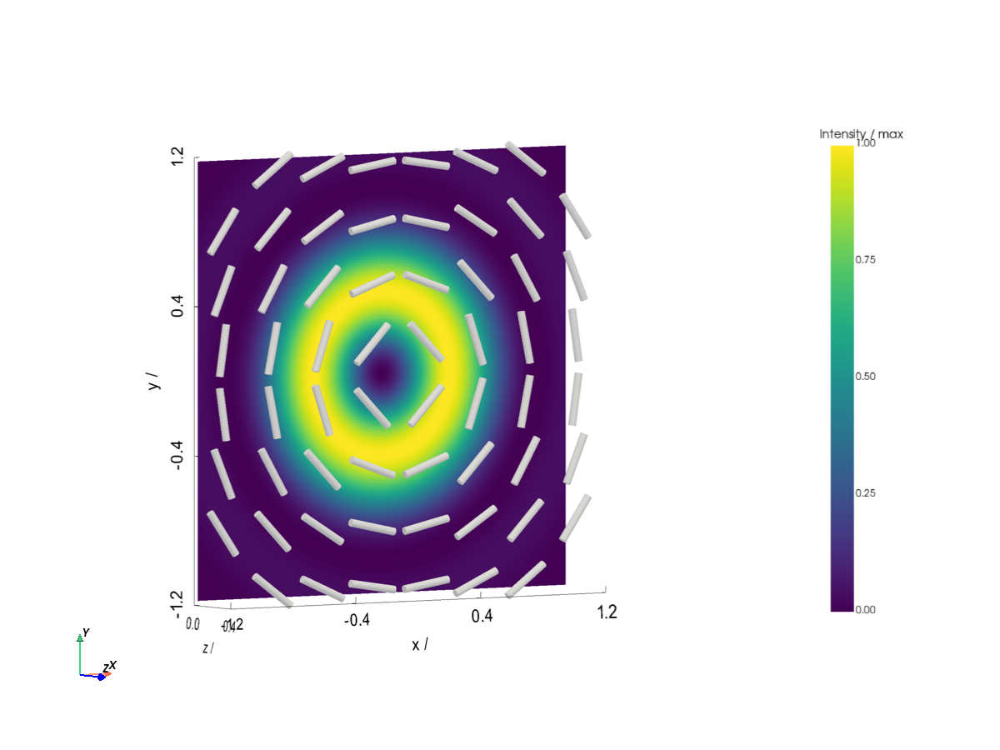

In [47]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_cv_2, "CV Azimuthal")

### 3.3. Hyperbolic X

Interchange the orbital charges relative to the radial construction. Inspect how the different spatial polarization winding redistributes the longitudinal field.

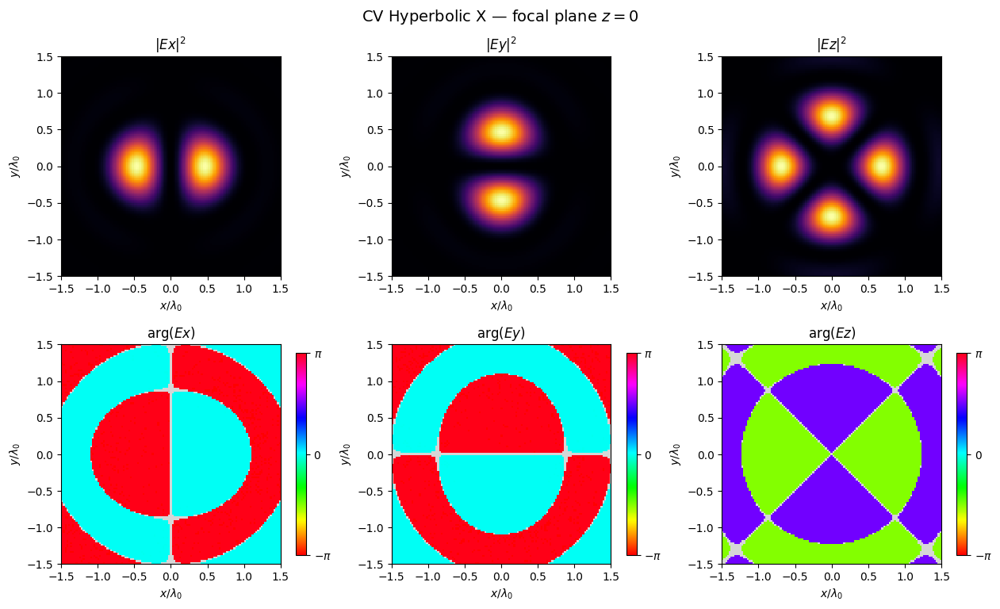

Peak |E|²: 0.270016; longitudinal share: 0.1936


In [48]:
# Compute the three complex components, then inspect intensity and phase.
E_cv_3 = calculate(cylindrical("Hyperbolic X"))
maps(E_cv_3, "CV Hyperbolic X")

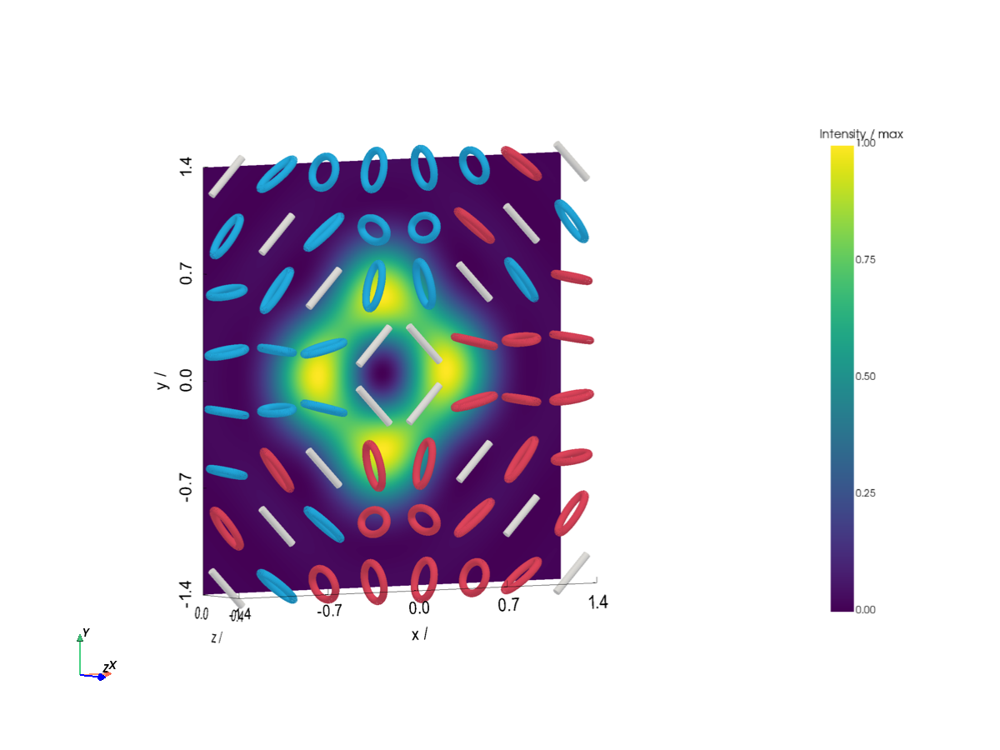

In [49]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_cv_3, "CV Hyperbolic X")

### 3.4. Hyperbolic Y

Change the relative sign of the opposite-charge terms. Compare the geometry and longitudinal field with Hyperbolic X.

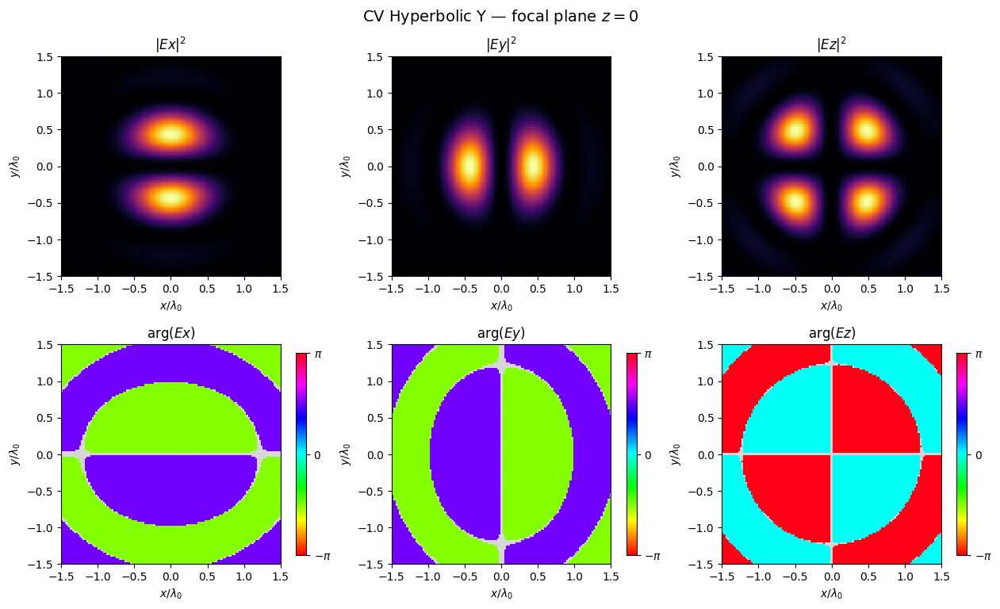

Peak |E|²: 0.269922; longitudinal share: 0.1987


In [50]:
# Compute the three complex components, then inspect intensity and phase.
E_cv_4 = calculate(cylindrical("Hyperbolic Y"))
maps(E_cv_4, "CV Hyperbolic Y")

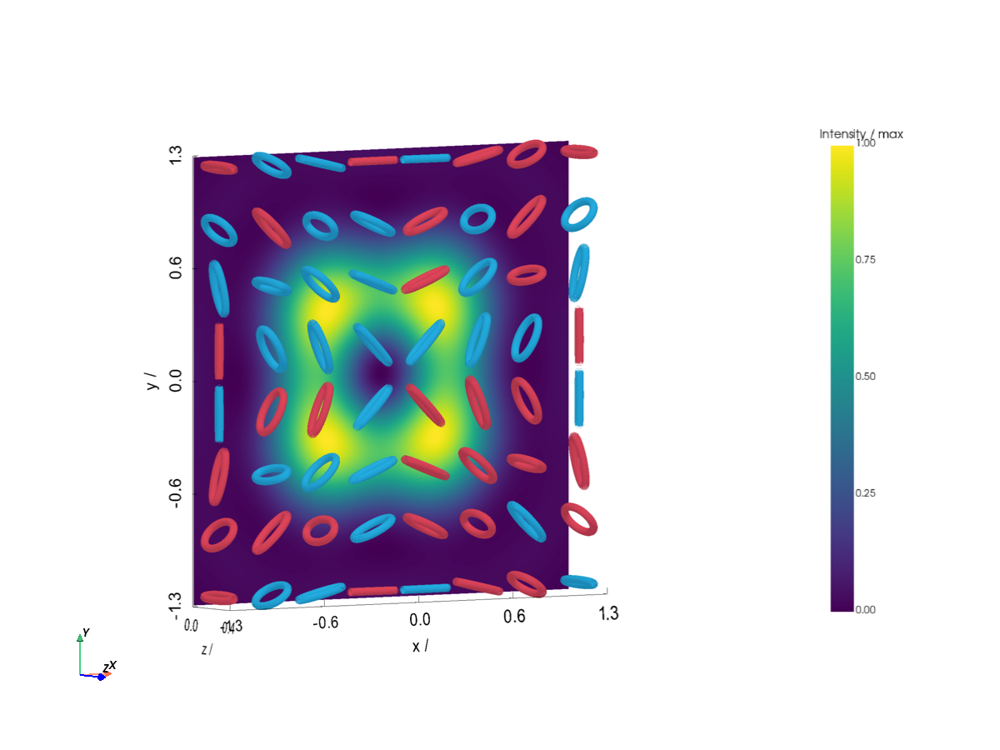

In [51]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_cv_4, "CV Hyperbolic Y")

## 4. Full-Poincaré beams

A full-Poincaré beam combines opposite circular polarization components with different spatial envelopes. The examples use the thesis-associated star, monstar and lemon input parameterization:

$$
\mathbf E_{\rm FP}=
\frac{1}{\sqrt2}
\left[
(\cos\beta_{\rm mix}\,U_{+1}-\sin\beta_{\rm mix}\,U_{-1})\mathbf e_R
+U_0\mathbf e_L
\right].
$$

Here $\beta_{\rm mix}$ is a mixing angle, distinct from the minor semiaxis $\boldsymbol\beta$. It is the argument called beta in the beam-construction function. The relative phase of the two circular components varies spatially, creating different incident polarization textures.

The names below describe the **incident** target textures in the source convention. Identifying a focused C-point as a star, monstar or lemon requires separate polarization-line winding and separatrix analysis. A sampled 3D ellipse plot alone does not establish the topology.

### 4.1. Star ($\beta_{\rm mix}=0$)

The R component carries only positive vortex charge while the L component is Gaussian. Inspect the focal polarization geometry near the axis.

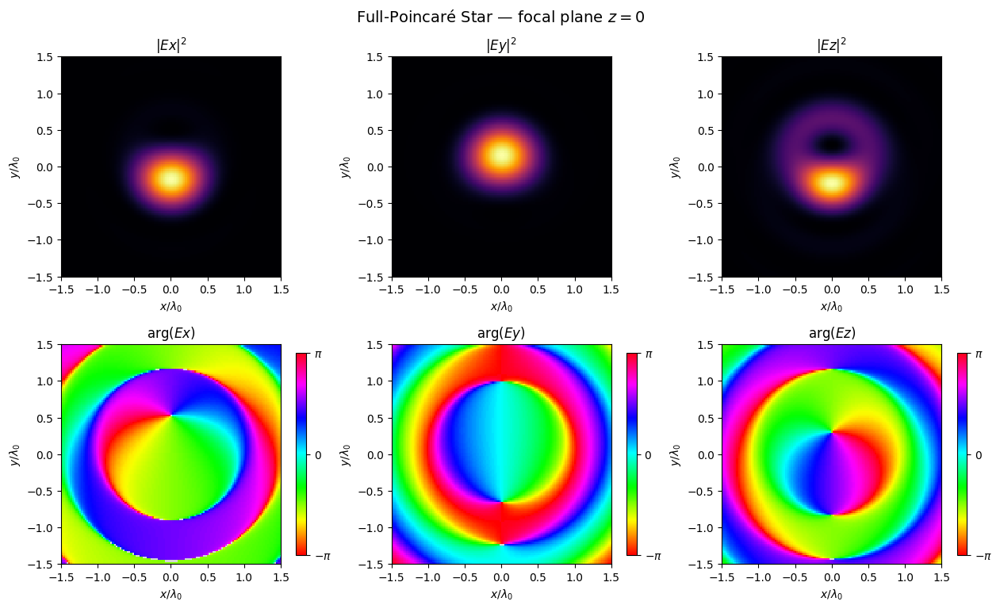

Peak |E|²: 1.16986; longitudinal share: 0.1486


In [52]:
# Compute the three complex components, then inspect intensity and phase.
E_fp_star = calculate(poincare(0))
maps(E_fp_star, "Full-Poincaré Star")

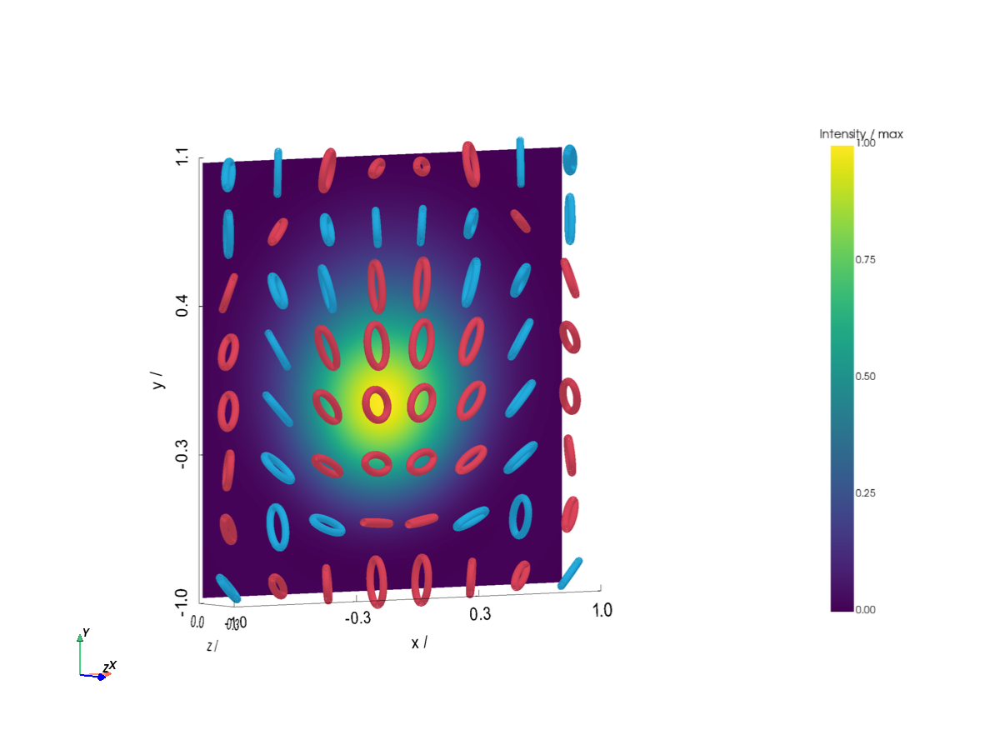

In [53]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_fp_star, "Full-Poincaré Star")

### 4.2. Monstar ($\beta_{\rm mix}=\pi/4$)

The R component contains both vortex charges with equal magnitude and opposite sign. Compare the resulting spatial anisotropy with the other two textures.

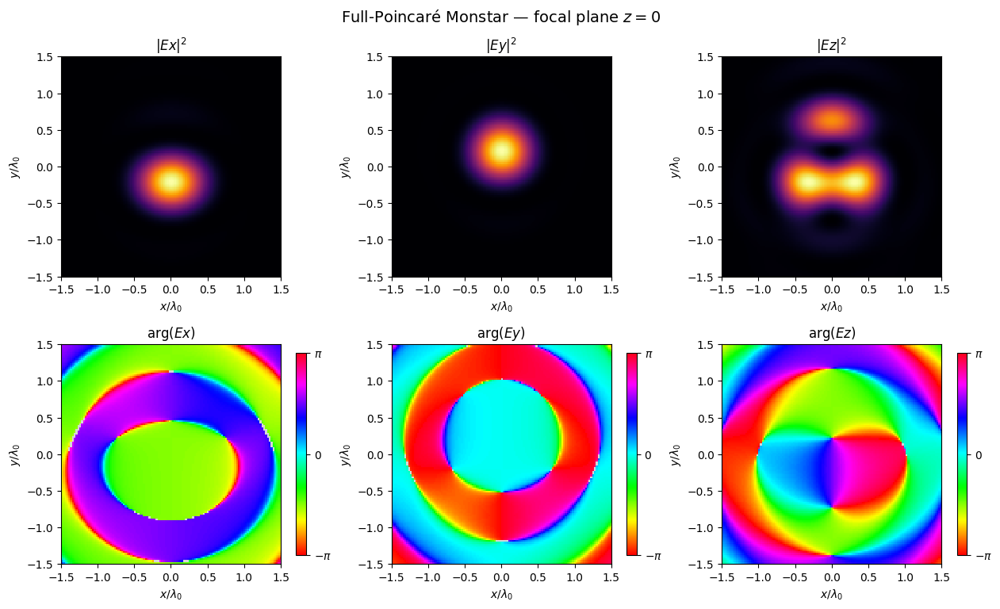

Peak |E|²: 1.11483; longitudinal share: 0.1485


In [54]:
# Compute the three complex components, then inspect intensity and phase.
E_fp_monstar = calculate(poincare(np.pi/4))
maps(E_fp_monstar, "Full-Poincaré Monstar")

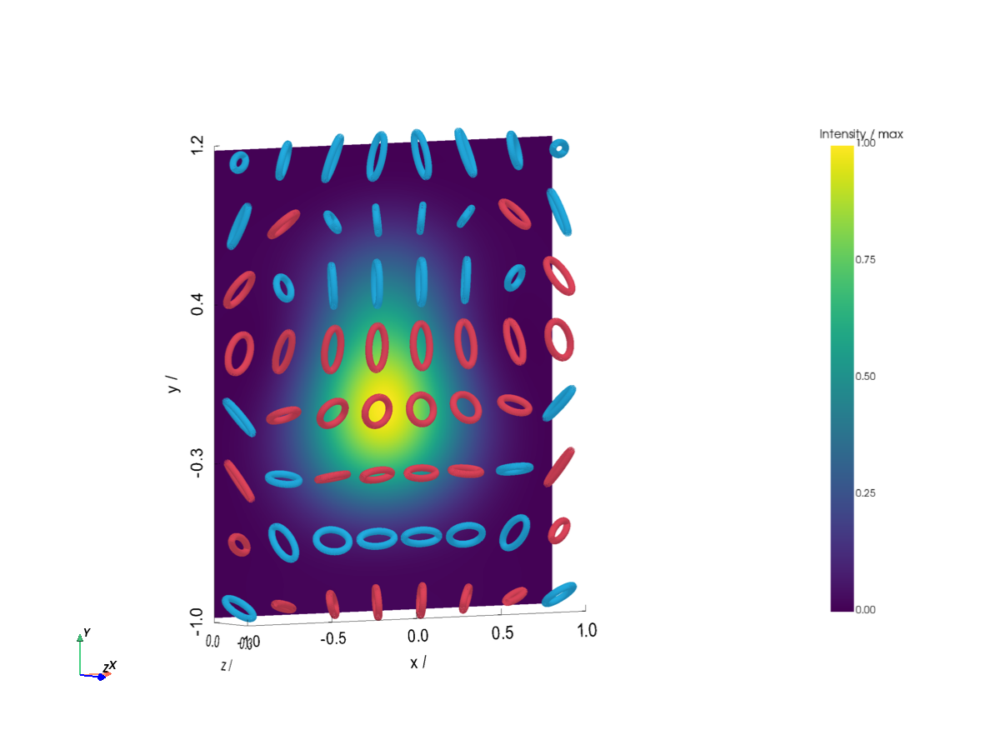

In [55]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_fp_monstar, "Full-Poincaré Monstar")

### 4.3. Lemon ($\beta_{\rm mix}=\pi/2$)

The R component carries only negative vortex charge, with a relative minus sign. Compare the focal complex components and local polarization with the star construction.

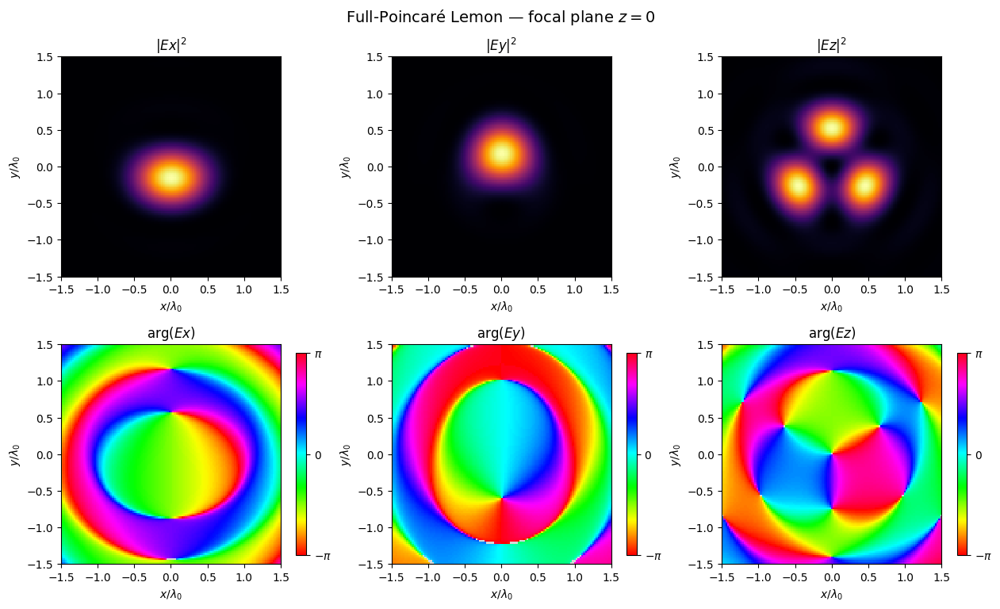

Peak |E|²: 1.0474; longitudinal share: 0.1485


In [56]:
# Compute the three complex components, then inspect intensity and phase.
E_fp_lemon = calculate(poincare(np.pi/2))
maps(E_fp_lemon, "Full-Poincaré Lemon")

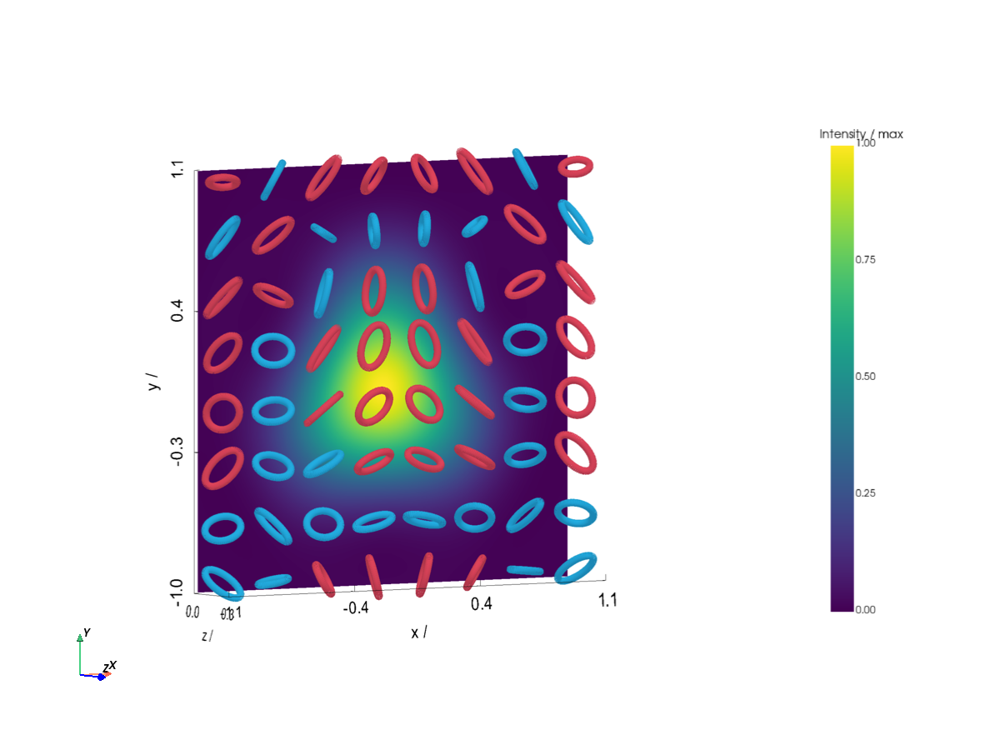

In [57]:
# Static focal-plane ellipse view; open the optional interactive HTML below.
pyvista_ellipses(E_fp_lemon, "Full-Poincaré Lemon")

## 5. Interpretation, validation and limitations

### 5.1. Physical consistency checks

When evaluating the examples, check the expected rotational symmetry of H/V Gaussian focusing, the on-axis longitudinal field of the radial beam, and the vanishing longitudinal field of the azimuthal beam. These checks follow from the ideal objective model. The notebook visualizations aid inspection but are not a substitute for quantitative regression tests.

### 5.2. Numerical convergence

Refine the polar-angle and radial grids independently, rerun the solver definition cell and recalculate the fields. Compare full complex fields on the same Cartesian coordinates using

$$
\epsilon_E=\frac{\|\mathbf E_{\rm test}-\mathbf E_{\rm ref}\|_2}{\|\mathbf E_{\rm ref}\|_2}.
$$

Use identical pupil envelopes, Jones coefficients, wavelength, NA, focal length and global phase convention. Compare individual Cartesian components where meaningful, and avoid relative phase errors at field zeros. Tutorial 01 includes an independent two-angle Richards–Wolf quadrature comparison. The interactive viewer does not change numerical resolution.

### 5.3. Scope and follow-up

The model excludes aberrations, refractive-index interfaces, evanescent fields and broadband effects. Only $z=0$ is computed here. The sampled three-dimensional ellipse geometry is not a topological classifier, and the intensity proxy is not a calibrated flux measurement. The incident modes have not been normalized to equal power.

Suggested exercises: vary NA and compare the longitudinal-field share; reverse circular polarization and orbital charge independently; increase sampling and compare complex fields; use the HTML viewer to inspect the relation between ellipse shape, principal axes and the directed normal.

### References

- B. Richards and E. Wolf, “Electromagnetic diffraction in optical systems, II. Structure of the image field in an aplanatic system,” Proceedings of the Royal Society A **253**, 358–379 (1959).
- M. F. Ferrer-García, PhD thesis, Chapter 2, Eqs. (2.1)–(2.10), and Appendix A. The analytical decomposition and pupil convention used here follow this source, with the longitudinal integrand correction discussed in Section A.6.
- [Tutorial 01 — Five Bessel-integral decomposition](https://github.com/mffg1993/TightFocusingSolutions/blob/main/tutorials/01_Thesis_Bessel_Integral_Decomposition.ipynb).

## 6. Numerical reference dataset (optional)

This section exports the **full complex focal fields** of all 25 beam configurations at z = 0, with a convergence report and machine-readable metadata. The saved fields use the same Cartesian grid as the atlas, but the numerical integrations are refined.

**To execute this section:** First run only the existing setup/import, optical-parameter, Jones/mode-definition, and five-integral solver cells. There is **no need to run any of the 25 figure cells**. If you already ran the entire atlas, simply execute the cells below.

| Calculation | Angular samples | Radial nodes |
| --- | ---: | ---: |
| Default | 401 | 251 |
| Intermediate | 801 | 1001 |
| Reference | 1601 | 2001 |

For each case we compare all complex components across the output grid:

$$
\epsilon_E=\frac{\|\mathbf E_{\mathrm{candidate}}-\mathbf E_{\mathrm{reference}}\|_2}
{\|\mathbf E_{\mathrm{reference}}\|_2}.
$$

**Scientific interpretation.** This quantifies **internal numerical convergence**, not agreement with an independent solution. The highest-resolution result is a *numerical reference*, not mathematically exact ground truth. Independent two-angle Richards–Wolf comparisons are provided in Tutorial 01.

This section does not modify the optical solver or existing plotting cells. It temporarily replaces the quadrature grids and resets the cached basis at every resolution; the original settings are restored afterwards.

In [58]:
# 6.1 — List the 25 beam definitions used in this notebook.
import json
import platform
import shutil
from pathlib import Path
import scipy
import pandas as pd
from tqdm.auto import tqdm

ref_cases = {}
states = {
    "H": JONES["X / H"], "V": JONES["Y / V"],
    "D": JONES["D (+45°)"], "A": JONES["A (-45°)"],
    "R": JONES["R"], "L": JONES["L"],
}
for label, vector in states.items():
    ref_cases["Gaussian_" + label] = gaussian(vector)
    ref_cases["LG_plus1_" + label] = lg(+1, vector)
    ref_cases["LG_minus1_" + label] = lg(-1, vector)
for kind in ["Radial", "Azimuthal", "Hyperbolic X", "Hyperbolic Y"]:
    ref_cases["CV_" + kind.replace(" ", "_")] = cylindrical(kind)
for label, beta in [("Star", 0), ("Monstar", np.pi/4), ("Lemon", np.pi/2)]:
    ref_cases["FP_" + label] = poincare(beta)

assert len(ref_cases) == 25 and RHO.shape == (N, N)
ref_root = Path("reference_data")
ref_name = f"z0_NA{round(NA*100):03d}"
ref_dir = ref_root / ref_name
ref_dir.mkdir(parents=True, exist_ok=True)
print("Configurations:", len(ref_cases), "; output grid:", (N, N))
print("Directory:", ref_dir.resolve())

Configurations: 25 ; output grid: (121, 121)
Directory: /content/reference_data/z0_NA085


### 6.2. Calculate and compare the fields

The reference calculation retains complex128 values and the original global-phase convention. We explicitly clear the memoized basis when changing the angular and radial grids. The final cell restores the original grid in a try/finally block.

The result is a convergence CSV listing the relative error of both coarser resolutions with respect to the finest calculation.

In [59]:
# 6.2 — Recalculate at three numerical resolutions; no visualization.
resolutions = {"default": (401, 251),
               "intermediate": (801, 1001),
               "reference": (1601, 2001)}
theta_original, radial_original = theta.copy(), radial_nodes.copy()
ref_results = {}
try:
    for tag, (nt, nr) in resolutions.items():
        theta = np.linspace(0, alpha, nt)
        radial_nodes = np.linspace(0, float(RHO.max()), nr)
        cached_basis.cache_clear()
        ref_results[tag] = {}
        for name, terms in tqdm(ref_cases.items(), desc=tag):
            E = np.asarray(calculate(terms), dtype=np.complex128)
            assert E.shape == (3, N, N) and np.all(np.isfinite(E))
            ref_results[tag][name] = E
finally:
    theta, radial_nodes = theta_original, radial_original
    cached_basis.cache_clear()

def reference_error(field, reference):
    denominator = np.linalg.norm(reference.ravel())
    if denominator == 0:
        raise ValueError("Reference field has zero norm.")
    return float(np.linalg.norm((field-reference).ravel()) / denominator)

records = []
for name in ref_cases:
    ref = ref_results["reference"][name]
    records.append({
        "beam": name,
        "default_vs_reference": reference_error(ref_results["default"][name], ref),
        "intermediate_vs_reference": reference_error(ref_results["intermediate"][name], ref)
    })
ref_convergence = pd.DataFrame(records)
display(ref_convergence.style.format({
    "default_vs_reference": "{:.3e}",
    "intermediate_vs_reference": "{:.3e}"
}))
ref_convergence.to_csv(ref_dir / "convergence.csv", index=False)
print("Max default error:", ref_convergence["default_vs_reference"].max())
print("Max intermediate error:", ref_convergence["intermediate_vs_reference"].max())
print("Cases improved:", int((ref_convergence["intermediate_vs_reference"]
                      < ref_convergence["default_vs_reference"]).sum()), "/ 25")

default:   0%|          | 0/25 [00:00<?, ?it/s]

intermediate:   0%|          | 0/25 [00:00<?, ?it/s]

reference:   0%|          | 0/25 [00:00<?, ?it/s]

,beam,default_vs_reference,intermediate_vs_reference
0,Gaussian_H,6.533e-05,3.267e-06
1,LG_plus1_H,8.529e-05,4.241e-06
2,LG_minus1_H,8.529e-05,4.241e-06
3,Gaussian_V,6.533e-05,3.267e-06
4,LG_plus1_V,8.529e-05,4.241e-06
5,LG_minus1_V,8.529e-05,4.241e-06
6,Gaussian_D,6.533e-05,3.267e-06
7,LG_plus1_D,8.529e-05,4.241e-06
8,LG_minus1_D,8.529e-05,4.241e-06
9,Gaussian_A,6.533e-05,3.267e-06


Max default error: 8.978697697402601e-05
Max intermediate error: 4.478346215722219e-06
Cases improved: 25 / 25


### 6.3. Save the reference fields

Each compressed NPZ file contains the complete complex field **E** with shape (3, N, N) in component order (Ex, Ey, Ez), separate Ex/Ey/Ez convenience arrays, the x and y coordinates, optical parameters, integration sizes, charges and **complex** Jones-mode coefficients. The metadata JSON records units and conventions.

The data are **not** normalized to equal incident power; do not compare absolute mode intensities without accounting for the incident pupil normalization.

In [60]:
# 6.3 — Save the fields and metadata to /content/reference_data in Colab.
metadata = {
    "project": "TightFocusingSolutions",
    "source_notebook": "02_Focal_Plane_Polarization_Atlas_PyVista.ipynb",
    "method": "Five Bessel integrals, Simpson quadrature, radial interpolation",
    "numerical_reference_not_exact_truth": True,
    "reference_resolution": {"n_theta": 1601, "n_radial": 2001},
    "comparison_resolutions": resolutions,
    "NA": float(NA), "n_medium": float(n_medium),
    "lambda0": float(lambda0), "focal_length": float(f),
    "focal_plane_z": 0.0,
    "cartesian_grid_size": int(N),
    "coordinate_units": "same length units as lambda0 (lambda0=1 by default)",
    "components": ["Ex", "Ey", "Ez"],
    "field_shape": ["component", "y", "x"],
    "dtype": "complex128",
    "time_convention": "exp(-i omega t)",
    "constant_lens_phase": "exp(-ikf) omitted",
    "incident_pupil": "q**abs(ell) * exp(-q**2); q=sin(theta)/sin(alpha)",
    "equal_incident_power_normalization": False,
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "scipy_version": scipy.__version__,
    "cases": list(ref_cases)
}

for name, terms in ref_cases.items():
    E = ref_results["reference"][name]
    charges = np.array([term[0] for term in terms], dtype=np.int32)
    jones_coeffs = np.array([[term[1], term[2]] for term in terms],
                             dtype=np.complex128)
    np.savez_compressed(
        ref_dir / f"{name}.npz",
        E=E, Ex=E[0], Ey=E[1], Ez=E[2],
        x=x, y=x.copy(), z=0.0,
        NA=NA, n_medium=n_medium, lambda0=lambda0, focal_length=f,
        ell=charges, jones_coefficients=jones_coeffs,
        n_theta=1601, n_radial=2001
    )

(ref_dir / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8")
assert len(list(ref_dir.glob("*.npz"))) == 25
print("Saved 25 complex fields, convergence.csv and metadata.json")

Saved 25 complex fields, convergence.csv and metadata.json


### 6.4. Download the dataset

In Colab, run the next cell. It creates a ZIP containing the 25 NPZ files, convergence.csv and metadata.json and requests a **browser download**. If browser downloads are blocked, find the ZIP under the Colab **Files** sidebar and use its Download option.

Colab session storage is temporary: download the ZIP or copy it to Google Drive before ending the session. **Nothing is uploaded to GitHub automatically.**

In [62]:
# 6.4 — ZIP and download the complete dataset.
zip_path = shutil.make_archive(
    "TightFocusing_Reference_Data_" + ref_name,
    "zip", root_dir=ref_root)
print(f"ZIP file: {zip_path} ({Path(zip_path).stat().st_size/1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Outside Colab: ZIP available in the working directory.")

# Optional: copy the ZIP into Google Drive rather than downloading:
# from google.colab import drive
# drive.mount("/content/drive")
# destination = Path("/content/drive/MyDrive/TightFocusingSolutions")
# destination.mkdir(parents=True, exist_ok=True)
# shutil.copy2(zip_path, destination / Path(zip_path).name)

ZIP file: /content/TightFocusing_Reference_Data_z0_NA085.zip (19.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 6.5. Load the reference data later

Extract the ZIP on your computer or into a Colab working folder. For example:

    import numpy as np
    with np.load("z0_NA085/FP_Lemon.npz") as saved:
        E_ref = saved["E"]            # complex128, (3, 121, 121)
        x_ref = saved["x"]
        coeffs = saved["jones_coefficients"]

    print(E_ref.shape, E_ref.dtype)

For reproducible comparisons, use identical wavelengths, numerical aperture, focal length, pupil coefficients, spatial coordinates and global-phase conventions. Differences in the axes or phase convention can produce large complex-vector errors even if intensity maps look similar.